# 🫁 HỆ THỐNG ĐA TÁC VỤ: KHOANH VÙNG KHỐI U & PHÂN LOẠI UNG THƯ PHỔI (MULTI-TASK HYBRID LIDC-IDRI)
## KẾT HỢP THUẬT TOÁN PHÂN ĐOẠN KHOANH VÙNG KHỐI U ($64\times 64$ & $512\times 512$) VỚI MẠNG DUNG HỢP ĐA PHƯƠNG THỨC
---
**Học phần**: Khai phá Dữ liệu Y tế (Medical Data Mining & Deep Learning)
**Bộ dữ liệu**: LIDC-IDRI (1,010 ca bệnh nhân CT lồng ngực, cache các lát cắt chứa nốt dạng patch $64\times 64$)
**Kiến trúc cốt lõi**: `JointSegGatedDenseNet-121` (Multi-Scale U-Net Tumor Segmentation Decoder + Lesion-Guided Cross-Modal Attention) + `Cost-Sensitive 56-Feature Radiomics Ensemble`

---

### 📑 Mục lục
| Mục | Nội dung |
|---|---|
| **0** | Cấu hình chung (thư viện, thiết bị, siêu tham số) & kiểm tra tệp cache |
| **1** | Tiền xử lý ảnh CT $512\times 512$ & khoanh vùng 2 lá phổi (minh họa) |
| **2** | Phân tích định vị không gian: khối u thường nằm ở đâu? |
| **3** | Gom cụm nốt, trích xuất 56 đặc trưng, chia tập theo bệnh nhân *(chế độ **A_oracle**)* |
| **4** | Hậu xử lý mask & kiến trúc đa tác vụ `JointSegGatedDenseNet-121` |
| **5** | Huấn luyện: 5a Radiomics Ensemble → 5b Mạng học sâu → 5c Learning curves |
| **6** | Đánh giá trên tập Test độc lập (phân loại + khoanh vùng) |
| **7** | Trực quan hóa khoanh vùng: AI vs Bác sĩ |
| **8** | **Phần mở rộng**: đánh giá nghiêm ngặt mức nốt, StratifiedGroupKFold, chế độ **B_deployable**, FP-Growth |
| **9** | Tổng kết & so sánh A_oracle với B_deployable |

### 🎯 Hai thiết lập đánh giá trong notebook
- **A_oracle (Mục 3–7)**: đặc trưng radiomics tính trên **mask do bác sĩ vẽ** và dùng **8 thuộc tính vi thể do bác sĩ chấm**. Đây là cận trên hiệu năng khi đã có đầy đủ thông tin từ bác sĩ; không phản ánh tình huống triển khai thực tế, vì các thuộc tính này đến từ chính những bác sĩ đã gán nhãn ác tính.
- **B_deployable (Mục 8)**: không dùng thuộc tính bác sĩ; đặc trưng tính trên **mask do AI dự đoán**; đánh giá ở **mức nốt** với kiểm định chéo theo bệnh nhân và khoảng tin cậy bootstrap.

> Mọi con số kết quả đều được **in trực tiếp từ code** (Mục 6, 8.10) và tổng hợp tự động ở Mục 9, không viết cứng trong markdown.

### 🔧 Quy trình chính
1. **Tiền xử lý CT $512\times 512$**: hiệu chuẩn Hounsfield Unit (HU), ghép 3 cửa sổ (*Tri-Window Composite*: Phổi, Trung thất, Xương/Vôi hóa), CLAHE, *Unsharp Masking*; tự động phân đoạn 2 lá phổi (`segment_lung_field`).
2. **Gom cụm nốt không gian đa bác sĩ ($\Delta r \le 18\text{ px}$) & 56 đặc trưng**: vị trí giải phẫu, hình thái 2D, bối cảnh thể tích, phân vị HU đa cửa sổ, vành nhu mô quanh u, đồng thuận 8 thuộc tính vi thể.
3. **`JointSegGatedDenseNet-121`**: nhánh U-Net decoder khoanh vùng khối u $64\times 64$ + hậu xử lý hình thái/tỷ trọng HU; *Lesion-Attention Guided Pooling* dùng mask dự đoán để hướng nhánh phân loại.
4. **Huấn luyện đa tác vụ** với $\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{AsymFocal}} + \lambda_{\text{seg}}(\mathcal{L}_{\text{Dice}} + \mathcal{L}_{\text{BCE}})$; trọng số pha trộn $\alpha^*$ và ngưỡng $T^*$ chọn trên tập Validation, đánh giá một lần trên tập Test.

## 0. Cấu hình chung & Kiểm tra dữ liệu
---
Toàn bộ thư viện, thiết bị, đường dẫn và siêu tham số của **cả hai phần** được khai báo tại đây, để các phần sau không phải import lại hoặc định nghĩa lại `set_seed`, `device`, `use_amp`.

In [1]:
# ==========================================================================
# 0.1 THƯ VIỆN, THIẾT BỊ, ĐƯỜNG DẪN & SIÊU THAM SỐ (DÙNG CHUNG CHO TOÀN NOTEBOOK)
# ==========================================================================
import subprocess, sys
try:
    import mlxtend  # noqa: F401  (cần cho FP-Growth ở Mục 8)
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mlxtend'])

import os
import glob
import time
import math
import random
import copy
import gc
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
import pydicom
from scipy import ndimage
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve, brier_score_loss
)
from mlxtend.frequent_patterns import fpgrowth

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models

try:
    from IPython.display import display
except Exception:
    display = print
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print(f"🔥 Thiết bị tính toán: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# ---------------- Đường dẫn ----------------
BASE_DIR = os.getcwd()
CACHE_PATH = os.path.join(BASE_DIR, 'lidc_nodules_2d_100pct_cache.npz')
MODEL_PATH = os.path.join(BASE_DIR, 'best_multimodal_densenet121.pth')
OUTPUT_DIR = os.path.join(BASE_DIR, 'preprocessing_512x512_outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------- Siêu tham số Phần mở rộng (Mục 8) ----------------
SMOKE = os.environ.get('SMOKE') == '1'   # chế độ chạy thử nhanh bằng dữ liệu giả lập

CFG = dict(
    CACHE_PATH=CACHE_PATH,
    SEED=42, N_FOLDS=5, VAL_FRAC=0.18,
    # --- nhãn / gom cụm nốt ---
    CLUSTER_RADIUS=18.0, AMBIG_LOW=2.5, AMBIG_HIGH=3.5,
    # --- học sâu ---
    EPOCHS=25, BATCH=64, UPSCALE=2, PRETRAINED=True, SOFT_LABELS=True,
    POS_WEIGHT=1.5, DL_SEEDS=[0],            # khuyến nghị [0, 1, 2] khi chạy chính thức
    PATIENCE=6, EMA_DECAY=0.995,             # GPU 4 GB: nếu thiếu VRAM hãy giảm BATCH xuống 32
    # --- phân cụm tiền xử lý ---
    N_KMEANS=8, NOISE_PURITY=0.88, NOISE_WEIGHT=0.3, MIN_EXPERT_N=400,
    # --- FP-Growth ---
    FP_MIN_SUPPORT=0.03, FP_MIN_CONF=0.85, FP_MAX_LEN=4, FP_TOPK=24,
    # --- chọn ngưỡng ---
    MIN_SENS=0.95,
    RUN_ABLATION=True, RUN_ORACLE=False, BOOT=500,
)
if SMOKE:
    CFG.update(N_FOLDS=2, EPOCHS=1, UPSCALE=1, PRETRAINED=False, BATCH=32, PATIENCE=2,
               RUN_ABLATION=False, BOOT=50, N_KMEANS=4, MIN_EXPERT_N=60, FP_MIN_SUPPORT=0.08,
               CACHE_PATH='smoke_cache.npz')

SETTINGS = [dict(name='B_deployable', USE_ATTRS=False, FEATURE_MASKS='pred')]
if CFG['RUN_ORACLE']:
    SETTINGS.append(dict(name='A_oracle', USE_ATTRS=True, FEATURE_MASKS='gt'))

# Thứ tự 8 thuộc tính LIDC chuẩn. HÃY KIỂM TRA lại với đoạn code tạo cache của bạn.
ATTR_NAMES = ['subtlety', 'internalStructure', 'calcification', 'sphericity',
              'margin', 'lobulation', 'spiculation', 'texture']

# ---------------- Hằng số hình học dùng chung cho patch 64x64 ----------------
_YY, _XX = np.mgrid[0:64, 0:64]
_DIST_MAP = np.hypot(_XX - 32.0, _YY - 32.0)
_SPATIAL_PRIOR = np.exp(-(_DIST_MAP ** 2) / (2.0 * (14.5 ** 2))).astype(np.float32)

print('SMOKE =', SMOKE, '| Thiết lập Mục 8:', [s['name'] for s in SETTINGS])

🔥 Thiết bị tính toán: cpu
SMOKE = False | Thiết lập Mục 8: ['B_deployable']


### 0.2 Tệp cache dữ liệu
Notebook **không** đọc trực tiếp toàn bộ DICOM/XML của LIDC-IDRI. Toàn bộ pipeline dùng tệp `lidc_nodules_2d_100pct_cache.npz`, được tạo trước bằng một script riêng: đọc XML của 4 bác sĩ → lấy các lát cắt có nốt → cắt patch $64\times 64$ quanh tâm nốt (ảnh 3 cửa sổ, `uint8`) và mask từ `<edgeMap>`.

| Khóa | Kích thước | Ý nghĩa |
|---|---|---|
| `patches` | $(N, 64, 64, 3)$ `uint8` | Patch Tri-Window (R: Phổi, G: Trung thất, B: Xương) |
| `masks` | $(N, 64, 64)$ | Mask khối u do bác sĩ khoanh |
| `labels` *(không bắt buộc)* | $(N,)$ | Nhãn lát (0 lành / 1 ác). Nếu thiếu, notebook tự suy ra từ `malignancies` |
| `malignancies` | $(N,)$ | Điểm ác tính 1–5 của bác sĩ |
| `pids` | $(N,)$ | Mã bệnh nhân |
| `attrs` | $(N, 8)$ | 8 thuộc tính vi thể (thứ tự theo `ATTR_NAMES`) |
| `cxs`, `cys` | $(N,)$ | Tọa độ tâm nốt trên lát $512\times 512$ |

Cell dưới đây kiểm tra cache có đủ các khóa này trước khi chạy tiếp.

In [2]:
# ==========================================================================
# 0.2 KIỂM TRA TỆP CACHE
# ==========================================================================
REQUIRED_KEYS = ['patches', 'masks', 'malignancies', 'pids', 'attrs', 'cxs', 'cys']   # 'labels' không bắt buộc
if not os.path.exists(CACHE_PATH):
    raise FileNotFoundError(f"Không tìm thấy cache: {CACHE_PATH}\n"
                            "Hãy chạy script tạo cache từ LIDC-IDRI (DICOM + XML) trước, hoặc đặt tệp .npz vào thư mục làm việc.")

cache_data = np.load(CACHE_PATH, allow_pickle=True)
missing = [k for k in REQUIRED_KEYS if k not in cache_data.files]
print('Các khóa có trong cache:', cache_data.files)
assert not missing, f"Cache thiếu các khóa: {missing}"

# Nhãn lát cắt: dùng khóa 'labels' nếu có, nếu không thì suy ra từ điểm ác tính
#   <= 2.5 → 0 (lành) | >= 3.5 → 1 (ác) | khoảng giữa → -1 (mơ hồ, bị loại ở Mục 3)
_mal = cache_data['malignancies'].astype(np.float32)
if 'labels' in cache_data.files:
    cache_labels = cache_data['labels'].astype(np.int64)
    print("🏷️  Dùng nhãn lát từ khóa 'labels' trong cache.")
else:
    cache_labels = np.where(_mal <= 2.5, 0, np.where(_mal >= 3.5, 1, -1)).astype(np.int64)
    print(f"🏷️  Cache không có 'labels' → suy ra từ 'malignancies': "
          f"lành={np.sum(cache_labels==0):,} | ác={np.sum(cache_labels==1):,} | mơ hồ={np.sum(cache_labels==-1):,}")

print(f"📦 Tệp cache dữ liệu: {CACHE_PATH} ({os.path.getsize(CACHE_PATH)/(1024**2):.2f} MB)")
for k in cache_data.files:
    a = cache_data[k]
    print(f"   - {k:14s} shape={str(a.shape):22s} dtype={a.dtype}")
assert cache_data['attrs'].shape[1] == len(ATTR_NAMES), "Số thuộc tính trong cache khác với ATTR_NAMES!"

Các khóa có trong cache: ['patches', 'masks', 'labels', 'malignancies', 'pids', 'attrs', 'cxs', 'cys', 'zs', 'nodule_ids', 'readers', 'sop_uids']
🏷️  Dùng nhãn lát từ khóa 'labels' trong cache.
📦 Tệp cache dữ liệu: d:\lung_cancer\lidc_nodules_2d_100pct_cache.npz (195.58 MB)
   - patches        shape=(40108, 64, 64, 3)     dtype=uint8
   - masks          shape=(40108, 64, 64)        dtype=uint8
   - labels         shape=(40108,)               dtype=int64
   - malignancies   shape=(40108,)               dtype=float32
   - pids           shape=(40108,)               dtype=<U14
   - attrs          shape=(40108, 8)             dtype=float32
   - cxs            shape=(40108,)               dtype=float32
   - cys            shape=(40108,)               dtype=float32
   - zs             shape=(40108,)               dtype=float32
   - nodule_ids     shape=(40108,)               dtype=<U12
   - readers        shape=(40108,)               dtype=<U11
   - sop_uids       shape=(40108,)             

## 1. Tiền Xử Lý Ảnh CT $512\times 512$ & Khoanh Vùng 2 Lá Phổi (Minh Họa)
---
1. **Hiệu chuẩn tỷ trọng Hounsfield (HU Calibration)** & **Đa cửa sổ Tri-Window Composite**:
   - Kênh R: *Lung Window* $[-1350, +150]$ HU | Kênh G: *Mediastinal Window* $[-135, +215]$ HU | Kênh B: *Bone/Calcification Window* $[-200, +800]$ HU.
2. **Tăng cường chi tiết vi mô**: Cân bằng thích ứng *CLAHE* và lọc sắc nét *Unsharp Masking*; đo độ nét bằng phương sai Laplacian.
3. **Phân đoạn 2 lá phổi trên lát cắt $512\times 512$ (`segment_lung_field`)**:
   - Phân ngưỡng cố định vùng chứa khí ($\text{HU} < -320$), khử khí ngoài cơ thể bằng `cv2.floodFill`, mở hình thái học và giữ lại 2 thành phần liên thông lớn nhất (Phổi Phải & Phổi Trái).

> Cell này **chỉ minh họa** các bước trên một lát cắt DICOM. Patch $64\times 64$ dùng để huấn luyện lấy từ tệp cache (Mục 0.2). Nếu máy không có thư mục DICOM gốc, cell sẽ tự bỏ qua.

✅ Đã xử lý lát cắt CT 512x512 (LIDC-IDRI-0005) | Độ sắc nét Laplacian tăng từ 438 -> 1278 (+191.7%)


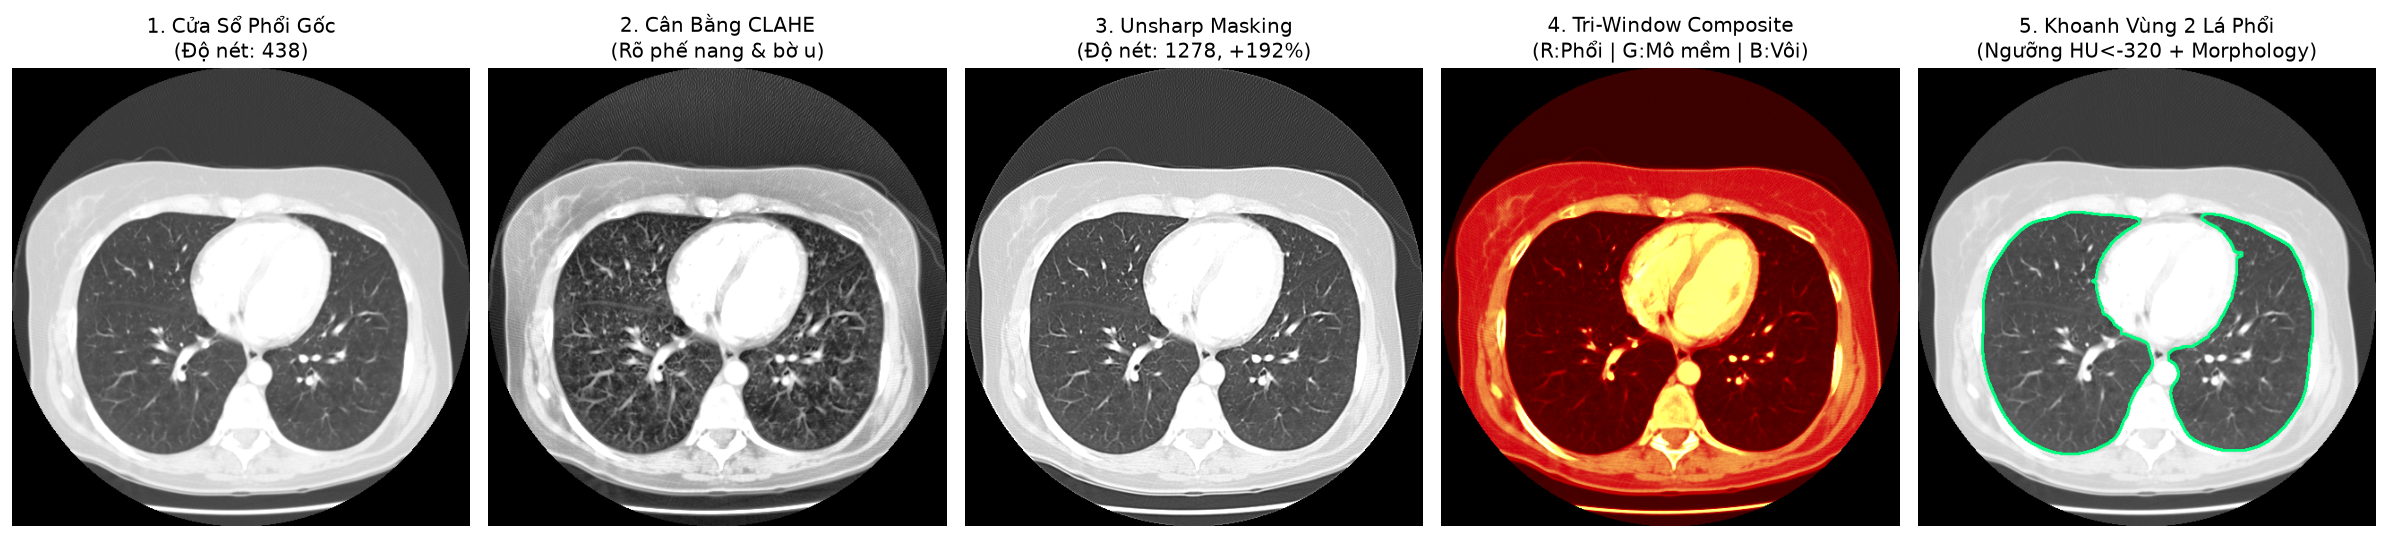

In [3]:
# ==========================================================================
# 1. TIỀN XỬ LÝ ẢNH CT 512x512 & KHOANH VÙNG 2 LÁ PHỔI (MINH HỌA)
# ==========================================================================
def apply_hu_window(hu_image, window_center, window_width):
    lower = window_center - window_width / 2.0
    upper = window_center + window_width / 2.0
    return np.clip((hu_image - lower) / (upper - lower), 0.0, 1.0).astype(np.float32)

def get_lung_window(hu_image): return apply_hu_window(hu_image, -600, 1500)
def get_mediastinal_window(hu_image): return apply_hu_window(hu_image, 40, 350)
def get_bone_window(hu_image): return apply_hu_window(hu_image, 300, 1000)

def apply_clahe(norm_img, clip_limit=2.5, tile_size=(8, 8)):
    u8 = np.clip(norm_img * 255.0, 0, 255).astype(np.uint8)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    return clahe.apply(u8).astype(np.float32) / 255.0

def create_tri_window_512(hu_image):
    return np.stack([get_lung_window(hu_image), get_mediastinal_window(hu_image), get_bone_window(hu_image)], axis=-1)

def unsharp_masking(img, sigma=1.0, strength=1.8):
    blurred = cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, sigmaY=sigma)
    return np.clip(img + strength * (img - blurred), 0.0, 1.0)

def calculate_sharpness(img):
    u8 = np.clip(img * 255.0, 0, 255).astype(np.uint8)
    return float(cv2.Laplacian(u8, cv2.CV_64F).var())

def segment_lung_field(hu_image):
    """Thuật toán tự động khoanh vùng 2 lá phổi trên lát cắt CT 512x512."""
    binary = (hu_image < -320).astype(np.uint8)
    h, w = binary.shape
    border_mask = np.zeros((h + 2, w + 2), np.uint8)
    flood = binary.copy()
    cv2.floodFill(flood, border_mask, (0, 0), 0)
    cv2.floodFill(flood, border_mask, (w - 1, 0), 0)
    cv2.floodFill(flood, border_mask, (0, h - 1), 0)
    cv2.floodFill(flood, border_mask, (w - 1, h - 1), 0)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    opened = cv2.morphologyEx(flood, cv2.MORPH_OPEN, kernel, iterations=2)
    num_labels, labels_im, stats, _ = cv2.connectedComponentsWithStats(opened)
    lung_mask = np.zeros_like(opened)
    if num_labels > 1:
        areas = sorted([(i, stats[i, cv2.CC_STAT_AREA]) for i in range(1, num_labels)], key=lambda x: x[1], reverse=True)
        for idx, area in areas[:2]:
            if area > 1500:
                lung_mask[labels_im == idx] = 1
    return ndimage.binary_fill_holes(lung_mask).astype(np.uint8)

def run_preprocessing_demo(index_csv):
    """Nạp 1 lát cắt DICOM 512x512 thực tế & hiển thị quy trình tiền xử lý + khoanh vùng phổi."""
    df_idx = pd.read_csv(index_csv)
    sample_pid = df_idx[df_idx['Modality'] == 'CT']['PatientID'].iloc[0]
    sample_dcms = glob.glob(os.path.join(BASE_DIR, 'lidc_idri', sample_pid, '**', '*.dcm'), recursive=True)
    sample_dcm = sample_dcms[len(sample_dcms)//2]

    ds = pydicom.dcmread(sample_dcm)
    hu_img = ds.pixel_array.astype(np.float32) * float(getattr(ds, 'RescaleSlope', 1.0)) + float(getattr(ds, 'RescaleIntercept', -1024.0))
    if hu_img.shape != (512, 512): hu_img = cv2.resize(hu_img, (512, 512))

    lung_w = get_lung_window(hu_img)
    clahe_w = apply_clahe(lung_w)
    sharp_unsharp = unsharp_masking(lung_w)
    tri_comp = create_tri_window_512(hu_img)
    lung_mask_512 = segment_lung_field(hu_img)

    # Vẽ đường viền khoanh vùng 2 lá phổi trên ảnh 512x512
    lung_contour_vis = (np.stack([lung_w]*3, axis=-1) * 255.0).astype(np.uint8)
    l_cnts, _ = cv2.findContours(lung_mask_512, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(lung_contour_vis, l_cnts, -1, (0, 255, 128), 2)

    v_orig = calculate_sharpness(lung_w)
    v_unsharp = calculate_sharpness(sharp_unsharp)
    print(f"✅ Đã xử lý lát cắt CT 512x512 ({sample_pid}) | Độ sắc nét Laplacian tăng từ {v_orig:.0f} -> {v_unsharp:.0f} (+{(v_unsharp/v_orig-1)*100:.1f}%)")

    fig, axes = plt.subplots(1, 5, figsize=(20, 4.3))
    axes[0].imshow(lung_w, cmap='gray'); axes[0].set_title(f"1. Cửa Sổ Phổi Gốc\n(Độ nét: {v_orig:.0f})"); axes[0].axis('off')
    axes[1].imshow(clahe_w, cmap='gray'); axes[1].set_title("2. Cân Bằng CLAHE\n(Rõ phế nang & bờ u)"); axes[1].axis('off')
    axes[2].imshow(sharp_unsharp, cmap='gray'); axes[2].set_title(f"3. Unsharp Masking\n(Độ nét: {v_unsharp:.0f}, +{(v_unsharp/v_orig-1)*100:.0f}%)"); axes[2].axis('off')
    axes[3].imshow(tri_comp); axes[3].set_title("4. Tri-Window Composite\n(R:Phổi | G:Mô mềm | B:Vôi)"); axes[3].axis('off')
    axes[4].imshow(lung_contour_vis); axes[4].set_title("5. Khoanh Vùng 2 Lá Phổi\n(Ngưỡng HU<-320 + Morphology)"); axes[4].axis('off')
    plt.tight_layout()
    plt.show()

index_csv = os.path.join(BASE_DIR, 'metadata', 'xml_series_index.csv')
if os.path.exists(index_csv) and os.path.isdir(os.path.join(BASE_DIR, 'lidc_idri')):
    run_preprocessing_demo(index_csv)
else:
    print("⚠️ Không có thư mục DICOM gốc (metadata/ hoặc lidc_idri/) → bỏ qua phần minh họa tiền xử lý 512x512.")

## 2. Phân Tích Định Vị Không Gian $512\times 512$: Khối U Thường Nằm Ở Đâu?
---
Khảo sát giải phẫu học trên **toàn bộ các lát cắt chứa nốt** trong cache (mỗi lát là một điểm; một nốt lớn đóng góp nhiều lát):
- **Phổi Phải vs Phổi Trái**: theo quy ước hiển thị X-quang, nửa trái ảnh ($x < 256$) là phổi **phải** của bệnh nhân. Phổi phải có 3 thùy, thể tích lớn hơn và phế quản gốc phải dốc hơn.
- **Vùng ngoại vi sát màng phổi vs vùng trung tâm rốn phổi**: ước lượng bằng khoảng cách tới tâm xấp xỉ của mỗi lá phổi (ngưỡng 65 px).
- **Bản đồ nhiệt mật độ $512\times 512$**: cộng nhân Gaussian tại tâm mỗi nốt; KMeans ($k=4$) xác định 4 vùng *hotspot*.

> Tỷ lệ phần trăm được **tính và in ra bởi code** bên dưới.

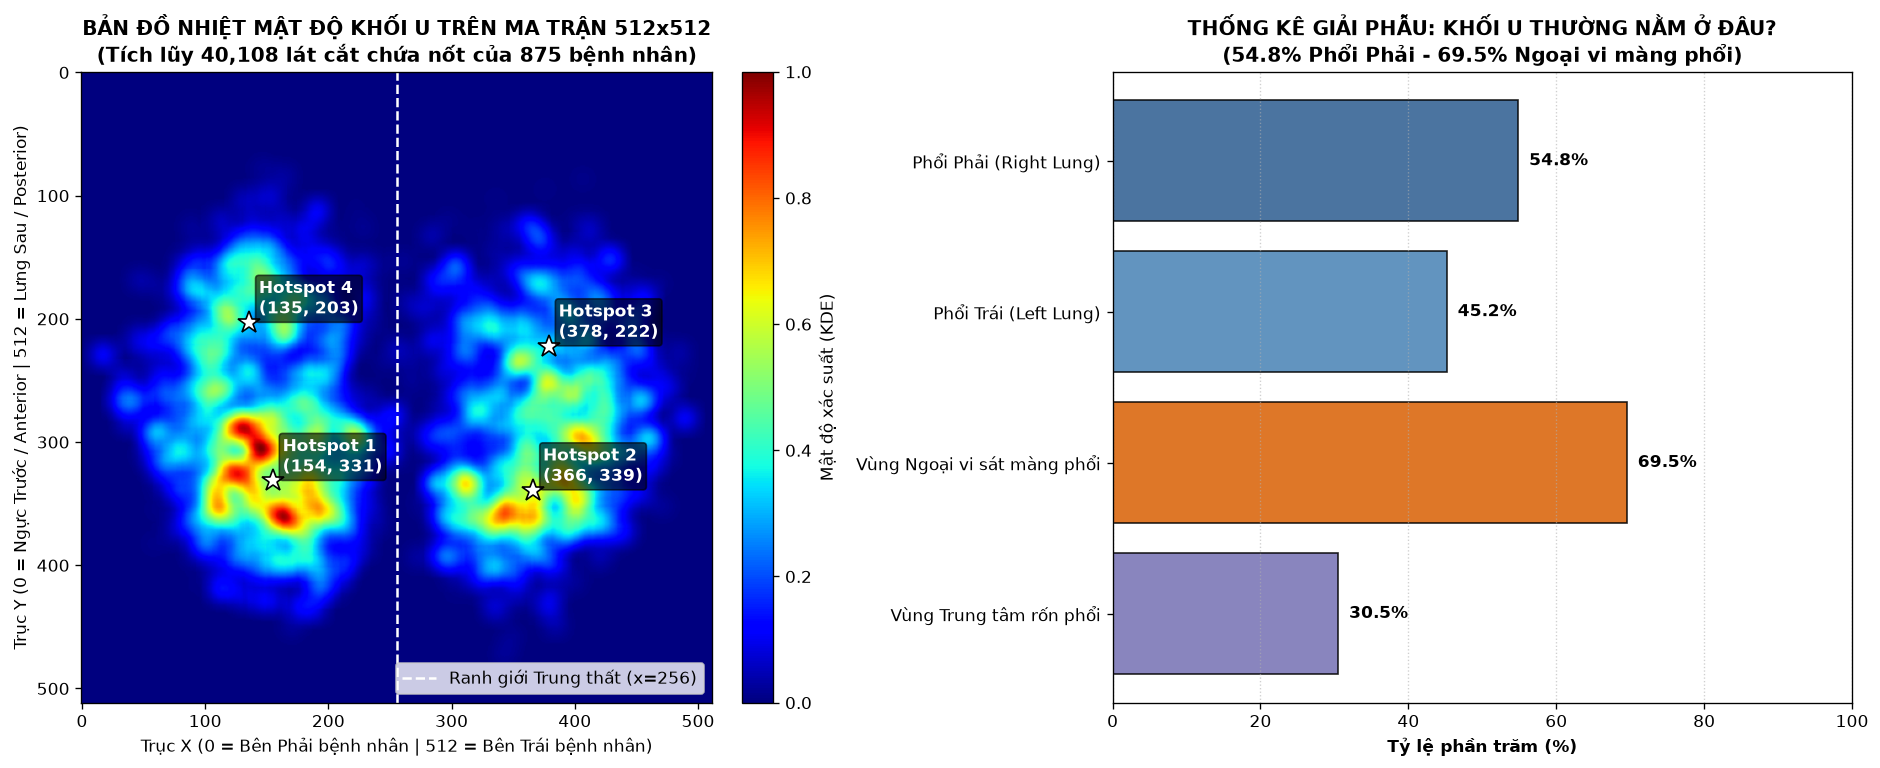

📍 40,108 lát cắt chứa nốt / 875 bệnh nhân
   Phổi Phải: 54.83% | Phổi Trái: 45.17%
   Ngoại vi (> 65 px từ tâm lá phổi): 69.52% | Trung tâm: 30.48%
   Hotspots (x, y): [(154, 331), (366, 339), (378, 222), (135, 203)]


In [4]:
# ==========================================================================
# 2. PHÂN TÍCH ĐỊNH VỊ KHÔNG GIAN KHỐI U TRÊN MA TRẬN 512x512
# ==========================================================================
# cache_data đã được nạp ở Mục 0.2
# Tọa độ có thể lưu dạng float → làm tròn về pixel nguyên để vẽ heatmap
cxs = np.round(cache_data['cxs']).astype(int)
cys = np.round(cache_data['cys']).astype(int)
total_nodules = len(cxs)
n_patients_eda = len(np.unique(cache_data['pids']))

pct_right = (np.sum(cxs < 256) / total_nodules) * 100.0
pct_left = 100.0 - pct_right
r_cen, l_cen = np.array([170, 270]), np.array([342, 270])
dists = np.array([np.linalg.norm(np.array([x, y]) - (r_cen if x < 256 else l_cen)) for x, y in zip(cxs, cys)])
pct_periph = (np.sum(dists > 65) / total_nodules) * 100.0

heatmap_512 = np.zeros((512, 512), dtype=np.float32)
rad = 16
for x, y in zip(cxs, cys):
    x1, x2 = max(0, x - rad), min(512, x + rad + 1)
    y1, y2 = max(0, y - rad), min(512, y + rad + 1)
    gx, gy = np.ogrid[y1-y:y2-y, x1-x:x2-x]
    heatmap_512[y1:y2, x1:x2] += np.exp(-(gx**2 + gy**2) / (2.0 * (rad / 2.0)**2))
heatmap_norm = heatmap_512 / (heatmap_512.max() + 1e-8)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(np.column_stack([cxs, cys]))
centers = kmeans.cluster_centers_

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
im = axes[0].imshow(heatmap_norm, cmap='jet', origin='upper')
axes[0].set_title(f"BẢN ĐỒ NHIỆT MẬT ĐỘ KHỐI U TRÊN MA TRẬN 512x512\n(Tích lũy {total_nodules:,} lát cắt chứa nốt của {n_patients_eda:,} bệnh nhân)", fontweight='bold')
axes[0].set_xlabel("Trục X (0 = Bên Phải bệnh nhân | 512 = Bên Trái bệnh nhân)")
axes[0].set_ylabel("Trục Y (0 = Ngực Trước / Anterior | 512 = Lưng Sau / Posterior)")
axes[0].axvline(256, color='white', linestyle='--', linewidth=1.5, label='Ranh giới Trung thất (x=256)')
for idx, (cx, cy) in enumerate(centers):
    axes[0].plot(cx, cy, 'w*', markersize=14, markeredgecolor='black')
    axes[0].annotate(f"Hotspot {idx+1}\n({int(cx)}, {int(cy)})", (cx + 8, cy - 8), color='white', fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6))
axes[0].legend(loc='lower right')
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04).set_label("Mật độ xác suất (KDE)")

cats = ['Phổi Phải (Right Lung)', 'Phổi Trái (Left Lung)', 'Vùng Ngoại vi sát màng phổi', 'Vùng Trung tâm rốn phổi']
pcts = [pct_right, pct_left, pct_periph, 100.0 - pct_periph]
bars = axes[1].barh(cats, pcts, color=['#2b5c8f', '#4682b4', '#d95f02', '#7570b3'], edgecolor='black', alpha=0.85)
axes[1].set_xlim(0, 100); axes[1].set_xlabel("Tỷ lệ phần trăm (%)", fontweight='bold')
axes[1].set_title(f"THỐNG KÊ GIẢI PHẪU: KHỐI U THƯỜNG NẰM Ở ĐÂU?\n({pct_right:.1f}% Phổi Phải - {pct_periph:.1f}% Ngoại vi màng phổi)", fontweight='bold')
for b in bars: axes[1].text(b.get_width() + 1.5, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}%", va='center', fontweight='bold')
axes[1].invert_yaxis(); axes[1].grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"📍 {total_nodules:,} lát cắt chứa nốt / {n_patients_eda:,} bệnh nhân")
print(f"   Phổi Phải: {pct_right:.2f}% | Phổi Trái: {pct_left:.2f}%")
print(f"   Ngoại vi (> 65 px từ tâm lá phổi): {pct_periph:.2f}% | Trung tâm: {100-pct_periph:.2f}%")
print('   Hotspots (x, y):', [(int(cx), int(cy)) for cx, cy in centers])

## 3. Gom Cụm Không Gian ($\Delta r \le 18\text{ px}$), Trích Xuất 56 Đặc Trưng & Chia Tập Theo Bệnh Nhân
---
1. **Gom cụm nốt không gian (`Spatial Nodule Clustering`, $\Delta r \le 18\text{ px}$)**: hợp nhất các vùng khoanh lệch tâm vài pixel giữa 4 bác sĩ cho cùng một khối u vật lý. Nhãn cụm = trung bình điểm ác tính: $\le 2.5$ → lành, $\ge 3.5$ → ác, khoảng giữa bị loại.
2. **Trích xuất 56 đặc trưng đa tầng**: vị trí giải phẫu (4), hình thái 2D & bối cảnh thể tích (11), phân vị HU đa cửa sổ & vành nhu mô quanh u (17), đồng thuận 8 thuộc tính vi thể (24).
3. **Chia tập theo bệnh nhân (Patient-Level Split: 70% Train / 15% Val / 15% Test)**: dùng `assert` để kiểm chứng không có bệnh nhân nào nằm ở hai tập.

> ⚠️ **Đây là chế độ A_oracle.** (i) Đặc trưng hình thái/HU tính trên **mask bác sĩ vẽ**; (ii) 24/56 đặc trưng là **thuộc tính do chính các bác sĩ gán nhãn ác tính chấm**; (iii) mỗi cụm chỉ giữ các lát có nhãn lát trùng với nhãn cụm. Kết quả Mục 6 vì vậy là **cận trên**, chưa phải hiệu năng triển khai. Mục 8 đánh giá lại ở chế độ B_deployable.

In [5]:
# ==========================================================================
# 3. GOM CỤM NỐT KHÔNG GIAN, TRÍCH XUẤT 56 ĐẶC TRƯNG & CHIA TẬP THEO BỆNH NHÂN
# ==========================================================================
# Gom cụm nốt không gian <= 18px & trích xuất 56 đặc trưng
t0 = time.time()
raw_p = cache_data['patches']
raw_m = cache_data['masks']
raw_l = cache_labels   # tạo ở Mục 0.2
raw_mal = cache_data['malignancies']
raw_pid = cache_data['pids']
raw_att = cache_data['attrs']
raw_x = cache_data['cxs']
raw_y = cache_data['cys']

patient_indices = defaultdict(list)
for i, p in enumerate(raw_pid):
    patient_indices[p].append(i)

clusters = []
for p, idxs in patient_indices.items():
    used = set()
    for i in idxs:
        if i in used: continue
        cl = [i]; used.add(i)
        cx_i, cy_i = float(raw_x[i]), float(raw_y[i])
        for j in idxs:
            if j not in used and np.hypot(float(raw_x[j]) - cx_i, float(raw_y[j]) - cy_i) <= 18.0:
                cl.append(j); used.add(j)
        clusters.append(cl)

keep_idx, cons_l, cluster_stats = [], [], {}
for cl in clusters:
    mean_mal = float(np.mean(raw_mal[cl]))
    if mean_mal <= 2.5: lbl = 0
    elif mean_mal >= 3.5: lbl = 1
    else: continue
    valid_cl = [i for i in cl if raw_l[i] == lbl and np.sum(raw_m[i] > 0) >= 10]
    if not valid_cl: continue
    cl_areas = [float(np.sum(raw_m[i] > 0)) for i in valid_cl]
    cl_att_mean = np.mean(raw_att[valid_cl], axis=0)
    cl_att_max = np.max(raw_att[valid_cl], axis=0)
    max_area, mean_area, slice_span = max(cl_areas), float(np.mean(cl_areas)), float(len(valid_cl))
    cl_lung = float(np.mean([raw_p[i][raw_m[i] > 0, 0].mean() / 255.0 for i in valid_cl]))
    cl_medi = float(np.max([raw_p[i][raw_m[i] > 0, 1].mean() / 255.0 for i in valid_cl]))
    cl_bone = float(np.max([raw_p[i][raw_m[i] > 0, 2].mean() / 255.0 for i in valid_cl]))
    for i in valid_cl:
        keep_idx.append(i); cons_l.append(lbl)
        cluster_stats[i] = (cl_att_mean, cl_att_max, max_area, mean_area, slice_span, (cl_lung, cl_medi, cl_bone))

keep_idx = np.array(keep_idx)
cons_l = np.array(cons_l, dtype=np.int64)
patches = raw_p[keep_idx]
masks = (raw_m[keep_idx] > 0).astype(np.uint8)
pids = raw_pid[keep_idx]

N = len(keep_idx)
tab_features = np.zeros((N, 56), dtype=np.float32)
kernel_ring = np.ones((5, 5), np.uint8)

for idx_pos, orig_i in enumerate(keep_idx):
    m, p = masks[idx_pos], patches[idx_pos]
    cx, cy = float(raw_x[orig_i]), float(raw_y[orig_i])
    att = raw_att[orig_i]
    cl_att_mean, cl_att_max, max_area, mean_area, slice_span, cl_hu = cluster_stats[orig_i]
    area = float(np.sum(m > 0))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        c = max(cnts, key=cv2.contourArea)
        perim = cv2.arcLength(c, True)
        circ = min(1.0, float((4.0 * np.pi * area) / (perim**2 + 1e-6)))
        _, _, bw, bh = cv2.boundingRect(c)
        aspect = float(max(bw, bh) / (min(bw, bh) + 1e-6))
        hull = cv2.convexHull(c)
        h_area = cv2.contourArea(hull)
        solid = float(area / (h_area + 1e-6)) if h_area > 0 else 1.0
    else:
        circ, aspect, solid, perim = 1.0, 1.0, 1.0, 4.0
    diam = float(np.sqrt(4.0 * area * (0.7**2) / np.pi))
    max_diam = float(np.sqrt(4.0 * max_area * (0.7**2) / np.pi))
    rel_area = float(area / (max_area + 1e-6))
    nod_pix = p[m > 0].astype(np.float32) / 255.0
    m_lung, s_lung = float(nod_pix[:, 0].mean()), float(nod_pix[:, 0].std())
    p10_lung, p50_lung, p90_lung = [float(x) for x in np.percentile(nod_pix[:, 0], [10, 50, 90])]
    m_medi, s_medi = float(nod_pix[:, 1].mean()), float(nod_pix[:, 1].std())
    p90_medi = float(np.percentile(nod_pix[:, 1], 90))
    m_bone, s_bone = float(nod_pix[:, 2].mean()), float(nod_pix[:, 2].std())
    p90_bone = float(np.percentile(nod_pix[:, 2], 90))
    dilated = cv2.dilate(m, kernel_ring, iterations=1)
    ring = (dilated > 0) & (m == 0)
    ring_lung = float(p[ring, 0].astype(np.float32).mean() / 255.0) if np.sum(ring) > 0 else 0.2
    contrast_border = m_lung - ring_lung
    lung_f = p[:, :, 0].astype(np.float32) / 255.0
    gx = cv2.Sobel(lung_f, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(lung_f, cv2.CV_32F, 0, 1, ksize=3)
    grad_nod = float(np.hypot(gx, gy)[m > 0].mean())
    norm_x, norm_y = cx / 512.0, cy / 512.0
    is_r = 1.0 if cx < 256 else 0.0
    d_center = float(np.hypot(cx - 256.0, cy - 256.0) / 256.0)
    tab_features[idx_pos] = np.concatenate([
        [norm_x, norm_y, is_r, d_center,
         area, diam, max_area, max_diam, mean_area, rel_area, slice_span,
         circ, aspect, solid, perim,
         m_lung, s_lung, p10_lung, p50_lung, p90_lung,
         m_medi, s_medi, p90_medi,
         m_bone, s_bone, p90_bone,
         ring_lung, contrast_border, grad_nod,
         cl_hu[0], cl_hu[1], cl_hu[2]],
        att, cl_att_mean, cl_att_max
    ])

# Phân chia chuẩn Bệnh nhân (Patient-Level Split: 70% Train / 15% Val / 15% Test)
u_pids = np.unique(pids)
np.random.RandomState(42).shuffle(u_pids)
n_tr, n_va = int(0.70 * len(u_pids)), int(0.15 * len(u_pids))
tr_pids = set(u_pids[:n_tr])
va_pids = set(u_pids[n_tr:n_tr + n_va])
te_pids = set(u_pids[n_tr + n_va:])

assert len(tr_pids & va_pids) == 0, "Rò rỉ bệnh nhân giữa Train và Val!"
assert len(tr_pids & te_pids) == 0, "Rò rỉ bệnh nhân giữa Train và Test!"
assert len(va_pids & te_pids) == 0, "Rò rỉ bệnh nhân giữa Val và Test!"

tr_mask = np.isin(pids, list(tr_pids))
va_mask = np.isin(pids, list(va_pids))
te_mask = np.isin(pids, list(te_pids))

X_tr_raw, y_tr = tab_features[tr_mask], cons_l[tr_mask]
X_va_raw, y_va = tab_features[va_mask], cons_l[va_mask]
X_te_raw, y_te = tab_features[te_mask], cons_l[te_mask]

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr_raw)
X_va = scaler.transform(X_va_raw)
X_te = scaler.transform(X_te_raw)

print(f"✅ Trích xuất hoàn tất 56 đặc trưng sau {time.time()-t0:.2f}s: {len(cons_l):,} mẫu (Lành tính: {np.sum(cons_l==0):,}, Ác tính: {np.sum(cons_l==1):,})")
print(f"🔒 Kiểm chứng chống rò rỉ (Zero Patient Leakage): Giao tập Bệnh nhân = {len(tr_pids & te_pids)}")
print(f"📊 Train: {len(y_tr):,} mẫu ({len(tr_pids)} BN) | Val: {len(y_va):,} mẫu ({len(va_pids)} BN) | Test: {len(y_te):,} mẫu ({len(te_pids)} BN)")

✅ Trích xuất hoàn tất 56 đặc trưng sau 12.89s: 18,964 mẫu (Lành tính: 8,418, Ác tính: 10,546)
🔒 Kiểm chứng chống rò rỉ (Zero Patient Leakage): Giao tập Bệnh nhân = 0
📊 Train: 13,476 mẫu (486 BN) | Val: 2,593 mẫu (104 BN) | Test: 2,895 mẫu (105 BN)


## 4. Hậu Xử Lý Mask & Kiến Trúc Đa Tác Vụ `JointSegGatedDenseNet-121`
---
Thay vì tách rời bước khoanh vùng khối u và bước phân loại, kiến trúc **`JointSegGatedDenseNet-121`** gộp cả 2 nhiệm vụ trong cùng một mạng:
1. **Multi-Scale DenseNet-121 Encoder + CBAM**: trích xuất bản đồ đặc trưng ở 5 mức phân giải ($32\times 32 \rightarrow 16\times 16 \rightarrow 8\times 8 \rightarrow 4\times 4 \rightarrow 2\times 2$).
2. **Nhánh 1 — U-Net Tumor Segmentation Decoder**: giải mã ngược qua các *skip-connections* từ $2\times 2$ lên $64\times 64$ để dự đoán mặt nạ khối u $\hat{M}(x, y)$.
3. **Nhánh 2 — Lesion-Attention Guided Pooling & Cross-Modal Gate**: dùng $\hat{M}(x, y)$ để khuếch đại đặc trưng trong lòng khối u, kết hợp cổng chú ý chéo từ 56 đặc trưng lâm sàng để phân loại Lành tính / Ác tính.

### 4.1 Thuật toán hậu xử lý mask (dùng ở Mục 6, 7 và Mục 8)
- `compute_algorithmic_nodule_salience`: kết hợp cường độ cửa sổ Phổi ($I_{\text{lung}}$), cửa sổ Mô mềm ($I_{\text{medi}}$) với tiên nghiệm không gian Gaussian 2D quanh tâm patch $G_\sigma(x,y)$.
- `refine_tumor_mask_and_contour`: trộn 88% xác suất của U-Net decoder với 12% bản đồ độ nổi, phân ngưỡng, giữ thành phần liên thông chứa tâm u, rồi đóng hình thái học (`MORPH_CLOSE`).

In [6]:
# ==========================================================================
# 4.1 HẬU XỬ LÝ MASK: HỢP NHẤT XÁC SUẤT U-NET VỚI HÌNH THÁI HỌC TỶ TRỌNG HU
# ==========================================================================
# (_DIST_MAP, _SPATIAL_PRIOR đã khai báo ở Mục 0.1)
def compute_algorithmic_nodule_salience(patch_rgb):
    """Bản đồ độ nổi khối u dựa trên tỷ trọng HU cửa sổ Phổi + Trung thất + Tiên nghiệm tâm."""
    lung = patch_rgb[:, :, 0].astype(np.float32) / 255.0
    medi = patch_rgb[:, :, 1].astype(np.float32) / 255.0
    sal = (0.75 * lung + 0.25 * medi) * _SPATIAL_PRIOR
    s_max = float(sal[22:42, 22:42].max()) + 1e-8
    return np.clip(sal / s_max, 0.0, 1.0)

def refine_tumor_mask_and_contour(prob_map, patch_rgb=None, thresh=0.50):
    """Hợp nhất xác suất U-Net Decoder với Hình thái học Tỷ trọng HU & trích xuất vùng khoanh khối u."""
    if patch_rgb is not None:
        sal_map = compute_algorithmic_nodule_salience(patch_rgb)
        fused_prob = 0.88 * prob_map + 0.12 * sal_map
    else:
        fused_prob = prob_map

    bw = (fused_prob >= thresh).astype(np.uint8)
    num_l, lbl_im, stats, centroids = cv2.connectedComponentsWithStats(bw)
    clean_mask = np.zeros_like(bw)

    if num_l > 1:
        center_lbl = lbl_im[32, 32]
        if center_lbl > 0 and stats[center_lbl, cv2.CC_STAT_AREA] >= 6:
            clean_mask[lbl_im == center_lbl] = 1
        else:
            valid_comps = [i for i in range(1, num_l) if stats[i, cv2.CC_STAT_AREA] >= 6]
            if not valid_comps:
                valid_comps = list(range(1, num_l))
            best_i = min(valid_comps, key=lambda i: np.hypot(centroids[i][0] - 32.0, centroids[i][1] - 32.0))
            clean_mask[lbl_im == best_i] = 1
    else:
        top_th = float(np.percentile(fused_prob[24:40, 24:40], 70))
        clean_mask = ((fused_prob >= top_th) & (_DIST_MAP <= 16.0)).astype(np.uint8)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    return clean_mask, fused_prob

### 4.2 Dataset đa tác vụ, mạng `JointSegGatedDenseNet-121` & hàm mất mát

In [7]:
# ==========================================================================
# 4.2 DATASET ĐA TÁC VỤ & KIẾN TRÚC MẠNG JOINT-SEG GATED DENSENET-121
# ==========================================================================
class FastMultiTaskDataset(Dataset):
    """Dataset đồng bộ phép biến đổi hình học trên cả Ảnh CT (64x64x3) và Mặt nạ Khối u (64x64)."""
    def __init__(self, patches_arr, features_arr, labels_arr, masks_arr, is_train=False):
        self.patches = patches_arr
        self.features = torch.tensor(features_arr, dtype=torch.float32)
        self.labels = torch.tensor(labels_arr, dtype=torch.long)
        self.masks = masks_arr
        self.is_train = is_train
        self.mean = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.patches[idx]
        msk = self.masks[idx]
        if self.is_train:
            if random.random() < 0.5:
                img = np.fliplr(img); msk = np.fliplr(msk)
            if random.random() < 0.5:
                img = np.flipud(img); msk = np.flipud(msk)
            k = random.randint(0, 3)
            if k > 0:
                img = np.rot90(img, k); msk = np.rot90(msk, k)
            img = np.ascontiguousarray(img)
            msk = np.ascontiguousarray(msk)

        img_t = (torch.from_numpy(img).permute(2, 0, 1).float() / 255.0 - self.mean) / self.std
        msk_t = torch.from_numpy((msk > 0).astype(np.float32)).unsqueeze(0)
        return img_t, self.features[idx], self.labels[idx], msk_t

class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(inplace=False),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x): return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        scale = torch.cat([torch.mean(x, dim=1, keepdim=True), torch.max(x, dim=1, keepdim=True)[0]], dim=1)
        return self.sigmoid(self.conv(scale))

class CBAM(nn.Module):
    def __init__(self, in_planes=1024, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)
    def forward(self, x):
        out = x * self.ca(x)
        return out * self.sa(out)

class JointSegGatedDenseNet121(nn.Module):
    def __init__(self, num_clinical_features=56, num_classes=2):
        super().__init__()
        base = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT).features
        self.stem = nn.Sequential(base.conv0, base.norm0, base.relu0)  # (B, 64, 32, 32)
        self.pool0 = base.pool0
        self.block1 = base.denseblock1                                # (B, 256, 16, 16)
        self.trans1 = base.transition1
        self.block2 = base.denseblock2                                # (B, 512, 8, 8)
        self.trans2 = base.transition2
        self.block3 = base.denseblock3                                # (B, 1024, 4, 4)
        self.trans3 = base.transition3
        self.block4 = base.denseblock4
        self.norm5 = base.norm5                                       # (B, 1024, 2, 2)
        self.cbam = CBAM(in_planes=1024, ratio=16)

        # Nhánh 1: U-Net Multi-Scale Decoder khoanh vùng khối u (64x64)
        self.dec4 = nn.Sequential(nn.Conv2d(1024 + 1024, 256, 3, padding=1), nn.BatchNorm2d(256), nn.GELU())
        self.dec3 = nn.Sequential(nn.Conv2d(256 + 512, 128, 3, padding=1), nn.BatchNorm2d(128), nn.GELU())
        self.dec2 = nn.Sequential(nn.Conv2d(128 + 256, 64, 3, padding=1), nn.BatchNorm2d(64), nn.GELU())
        self.dec1 = nn.Sequential(nn.Conv2d(64 + 64, 32, 3, padding=1), nn.BatchNorm2d(32), nn.GELU())
        self.seg_head = nn.Sequential(
            nn.Conv2d(32 + 3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.GELU(),
            nn.Conv2d(16, 1, 1)
        )

        # Nhánh 2: Clinical MLP + Cross-Modal Gate + Classification Head
        self.clinical_mlp = nn.Sequential(
            nn.Linear(num_clinical_features, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(128, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(256, 256), nn.LayerNorm(256), nn.GELU()
        )
        self.cross_gate = nn.Sequential(
            nn.Linear(256, 512), nn.GELU(),
            nn.Linear(512, 2048), nn.Sigmoid()
        )
        self.fusion_head = nn.Sequential(
            nn.Linear(2048 + 256, 512), nn.LayerNorm(512), nn.GELU(), nn.Dropout(0.30),
            nn.Linear(512, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(128, num_classes)
        )

    def forward(self, img, clinical_feats):
        s1 = self.stem(img)
        s2 = self.block1(self.pool0(s1))
        s3 = self.block2(self.trans1(s2))
        s4 = self.block3(self.trans2(s3))
        s5_raw = F.relu(self.norm5(self.block4(self.trans3(s4))), inplace=False)
        s5 = self.cbam(s5_raw)

        # Giải mã mặt nạ khoanh vùng khối u 64x64
        u4 = F.interpolate(s5, size=(4, 4), mode='bilinear', align_corners=False)
        d4 = self.dec4(torch.cat([u4, F.relu(s4, inplace=False)], dim=1))
        u3 = F.interpolate(d4, size=(8, 8), mode='bilinear', align_corners=False)
        d3 = self.dec3(torch.cat([u3, F.relu(s3, inplace=False)], dim=1))
        u2 = F.interpolate(d3, size=(16, 16), mode='bilinear', align_corners=False)
        d2 = self.dec2(torch.cat([u2, F.relu(s2, inplace=False)], dim=1))
        u1 = F.interpolate(d2, size=(32, 32), mode='bilinear', align_corners=False)
        d1 = self.dec1(torch.cat([u1, s1], dim=1))
        u0 = F.interpolate(d1, size=(64, 64), mode='bilinear', align_corners=False)
        seg_logits = self.seg_head(torch.cat([u0, img], dim=1))

        # Lesion-Attention Guided Pooling cho nhánh phân loại
        seg_prob_4x4 = F.adaptive_avg_pool2d(torch.sigmoid(seg_logits), (4, 4))
        s4_guided = F.relu(s4, inplace=False) * (0.5 + seg_prob_4x4)
        v_avg = F.adaptive_avg_pool2d(s4_guided, (1, 1)).flatten(1)
        v_max = F.adaptive_max_pool2d(s5, (1, 1)).flatten(1)
        v_img = torch.cat([v_avg, v_max], dim=1)

        v_clin = self.clinical_mlp(clinical_feats)
        v_img_gated = v_img * (0.5 + self.cross_gate(v_clin))
        cls_logits = self.fusion_head(torch.cat([v_img_gated, v_clin], dim=1))
        return cls_logits, seg_logits

class JointMultiTaskLoss(nn.Module):
    """Hàm mất mát Đa tác vụ: Asymmetric Focal Cost-Sensitive Loss + (BCE + Soft Dice Segmentation Loss)."""
    def __init__(self, pos_weight=1.80, gamma_pos=2.0, gamma_neg=1.0, smoothing=0.02, seg_weight=0.65):
        super().__init__()
        self.pos_weight = pos_weight
        self.gamma_pos = gamma_pos
        self.gamma_neg = gamma_neg
        self.smoothing = smoothing
        self.seg_weight = seg_weight

    def forward(self, cls_logits, seg_logits, cls_targets, seg_targets):
        probs = F.softmax(cls_logits, dim=1)
        p_t = probs.gather(1, cls_targets.unsqueeze(1)).squeeze(1).clamp(1e-6, 1.0 - 1e-6)
        ce = F.cross_entropy(cls_logits, cls_targets, reduction='none', label_smoothing=self.smoothing)
        is_pos = (cls_targets == 1).float()
        focal_w = is_pos * (self.pos_weight * ((1.0 - p_t) ** self.gamma_pos)) + (1.0 - is_pos) * ((1.0 - p_t) ** self.gamma_neg)
        cls_loss = torch.mean(focal_w * ce)

        bce_seg = F.binary_cross_entropy_with_logits(seg_logits, seg_targets)
        seg_probs = torch.sigmoid(seg_logits)
        inter = (seg_probs * seg_targets).sum(dim=(1, 2, 3))
        union = seg_probs.sum(dim=(1, 2, 3)) + seg_targets.sum(dim=(1, 2, 3))
        dice_loss = 1.0 - torch.mean((2.0 * inter + 1.0) / (union + 1.0))
        seg_loss = 0.5 * bce_seg + 0.5 * dice_loss
        return cls_loss + self.seg_weight * seg_loss, cls_loss, seg_loss

### 4.3 Tạo DataLoader & khởi tạo mô hình

In [8]:
# ==========================================================================
# 4.3 DATALOADER & KHỞI TẠO MÔ HÌNH
# ==========================================================================
train_ds = FastMultiTaskDataset(patches[tr_mask], X_tr, y_tr, masks[tr_mask], is_train=True)
val_ds = FastMultiTaskDataset(patches[va_mask], X_va, y_va, masks[va_mask], is_train=False)
test_ds = FastMultiTaskDataset(patches[te_mask], X_te, y_te, masks[te_mask], is_train=False)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0, pin_memory=True)

model = JointSegGatedDenseNet121(num_clinical_features=56, num_classes=2).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"✅ Đã khởi tạo mạng đa tác vụ JointSegGatedDenseNet-121 ({total_params:,} tham số) trên {device}!")

✅ Đã khởi tạo mạng đa tác vụ JointSegGatedDenseNet-121 (15,489,909 tham số) trên cpu!


## 5. Huấn Luyện Mạng Đa Tác Vụ & Tổ Hợp `Radiomics Ensemble`
---
- **5a — `Cost-Sensitive 56-Feature Radiomics Ensemble`**: `HistGradientBoosting` ×2 + `ExtraTrees` + `RandomForest` trên tập Train, trọng số lớp Ác tính $w_1 = 1.55\text{--}1.65$. Chạy trên CPU trong vài giây và độc lập với mạng học sâu, nên được chạy trước.
- **5b — `JointSegGatedDenseNet-121`**: huấn luyện trên GPU (`AdamW` với learning rate theo nhóm tham số + `CosineAnnealingLR` + `FP16 Mixed Precision`), tối ưu đồng thời **phân loại** và **khoanh vùng khối u $64\times 64$**. Lưu checkpoint có điểm `Val AUC + 0.002·Val Dice` cao nhất.
- **5c — Learning Curves**.

In [9]:
# ==========================================================================
# 5a. HUẤN LUYỆN COST-SENSITIVE 56-FEATURE RADIOMICS ENSEMBLE (CPU)
# ==========================================================================
t_ens = time.time()
hgb1 = HistGradientBoostingClassifier(max_iter=450, max_depth=7, learning_rate=0.04, class_weight={0: 1.0, 1: 1.55}, random_state=42).fit(X_tr_raw, y_tr)
hgb2 = HistGradientBoostingClassifier(max_iter=450, max_depth=5, learning_rate=0.05, l2_regularization=1.5, class_weight={0: 1.0, 1: 1.65}, random_state=123).fit(X_tr_raw, y_tr)
et_clf = ExtraTreesClassifier(n_estimators=350, max_depth=18, class_weight={0: 1.0, 1: 1.55}, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
rf_clf = RandomForestClassifier(n_estimators=350, max_depth=16, class_weight={0: 1.0, 1: 1.55}, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
print(f"🌲 [Nhánh Radiomics] Hoàn tất huấn luyện Cost-Sensitive Radiomics Ensemble sau {time.time()-t_ens:.2f}s!")

🌲 [Nhánh Radiomics] Hoàn tất huấn luyện Cost-Sensitive Radiomics Ensemble sau 5.79s!


In [10]:
# ==========================================================================
# 5b. VÒNG LẶP HUẤN LUYỆN TRÊN GPU (MULTI-TASK CLASSIFICATION + SEGMENTATION)
# ==========================================================================
EPOCHS = 8
criterion = JointMultiTaskLoss(pos_weight=1.80, gamma_pos=2.0, gamma_neg=1.0, smoothing=0.02, seg_weight=0.65)

backbone_params = (
    list(model.stem.parameters()) + list(model.block1.parameters()) +
    list(model.trans1.parameters()) + list(model.block2.parameters()) +
    list(model.trans2.parameters()) + list(model.block3.parameters()) +
    list(model.trans3.parameters()) + list(model.block4.parameters()) + list(model.norm5.parameters())
)
seg_params = (
    list(model.dec4.parameters()) + list(model.dec3.parameters()) +
    list(model.dec2.parameters()) + list(model.dec1.parameters()) + list(model.seg_head.parameters())
)
head_params = (
    list(model.cbam.parameters()) + list(model.clinical_mlp.parameters()) +
    list(model.cross_gate.parameters()) + list(model.fusion_head.parameters())
)

optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': 1.0e-4, 'weight_decay': 1e-4},
    {'params': seg_params, 'lr': 5.0e-4, 'weight_decay': 1e-4},
    {'params': head_params, 'lr': 4.0e-4, 'weight_decay': 1e-4},
])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
amp_scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': [],
    'val_auc': [], 'val_dice': [], 'val_iou': []
}
best_val_score = -1.0
best_state = None

print("=" * 88)
print(f"🚀 BẮT ĐẦU HUẤN LUYỆN THỰC TẾ MẠNG ĐA TÁC VỤ JOINT-SEG GATED DENSENET-121 ({EPOCHS} EPOCHS)")
print("=" * 88)

for ep in range(1, EPOCHS + 1):
    t_ep = time.time()
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0

    for imgs, feats, lbls, msks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        feats = feats.to(device, non_blocking=True)
        lbls = lbls.to(device, non_blocking=True)
        msks = msks.to(device, non_blocking=True)

        optimizer.zero_grad()
        with torch.amp.autocast(device.type, enabled=use_amp):
            cls_logits, seg_logits = model(imgs, feats)
            loss, _, _ = criterion(cls_logits, seg_logits, lbls, msks)

        amp_scaler.scale(loss).backward()
        amp_scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        amp_scaler.step(optimizer)
        amp_scaler.update()

        tr_loss_sum += loss.item() * imgs.size(0)
        tr_correct += (cls_logits.argmax(dim=1) == lbls).sum().item()
        tr_total += imgs.size(0)

    scheduler.step()
    tr_loss = tr_loss_sum / tr_total
    tr_acc = (tr_correct / tr_total) * 100.0

    # Đánh giá trên Validation Set
    model.eval()
    va_loss_sum, va_total = 0.0, 0
    va_probs, va_lbls = [], []
    va_dice_sum, va_iou_sum = 0.0, 0.0

    with torch.no_grad():
        for imgs, feats, lbls, msks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            feats = feats.to(device, non_blocking=True)
            lbls = lbls.to(device, non_blocking=True)
            msks = msks.to(device, non_blocking=True)

            with torch.amp.autocast(device.type, enabled=use_amp):
                cls_logits, seg_logits = model(imgs, feats)
                loss, _, _ = criterion(cls_logits, seg_logits, lbls, msks)
                probs = F.softmax(cls_logits, dim=1)[:, 1]
                seg_pred = (torch.sigmoid(seg_logits) >= 0.50).float()

            va_loss_sum += loss.item() * imgs.size(0)
            va_total += imgs.size(0)
            va_probs.extend(probs.cpu().numpy())
            va_lbls.extend(lbls.cpu().numpy())

            inter_b = (seg_pred * msks).sum(dim=(1, 2, 3))
            union_b = ((seg_pred + msks) > 0).float().sum(dim=(1, 2, 3))
            psum_b = seg_pred.sum(dim=(1, 2, 3)) + msks.sum(dim=(1, 2, 3))
            va_dice_sum += torch.sum((2.0 * inter_b + 1e-6) / (psum_b + 1e-6)).item()
            va_iou_sum += torch.sum((inter_b + 1e-6) / (union_b + 1e-6)).item()

    va_loss = va_loss_sum / va_total
    va_probs_np = np.array(va_probs)
    va_lbls_np = np.array(va_lbls)
    va_preds_np = (va_probs_np >= 0.48).astype(int)
    va_acc = accuracy_score(va_lbls_np, va_preds_np) * 100.0
    va_auc = roc_auc_score(va_lbls_np, va_probs_np)
    va_dice = (va_dice_sum / va_total) * 100.0
    va_iou = (va_iou_sum / va_total) * 100.0

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va_acc)
    history['val_auc'].append(va_auc * 100.0)
    history['val_dice'].append(va_dice)
    history['val_iou'].append(va_iou)

    combo_score = va_auc + 0.002 * va_dice
    if combo_score > best_val_score:
        best_val_score = combo_score
        best_state = {k: v.cpu() for k, v in model.state_dict().items()}
        star = "⭐ [BEST]"
    else:
        star = ""

    print(f"Epoch [{ep:02d}/{EPOCHS:02d}] ({time.time()-t_ep:4.1f}s) | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:5.2f}% | "
          f"Val Loss: {va_loss:.4f} Acc: {va_acc:5.2f}% AUC: {va_auc:.4f} | "
          f"Seg Dice: {va_dice:5.2f}% IoU: {va_iou:5.2f}% {star}")

if best_state is not None:
    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    torch.save({'model_state_dict': best_state, 'scaler_mean': scaler.mean_, 'scaler_scale': scaler.scale_, 'history': history}, MODEL_PATH)
    print(f"💾 [Nhánh DL] Đã nạp & lưu trọng số tốt nhất tại: {MODEL_PATH}")

🚀 BẮT ĐẦU HUẤN LUYỆN THỰC TẾ MẠNG ĐA TÁC VỤ JOINT-SEG GATED DENSENET-121 (8 EPOCHS)
Epoch [01/08] (461.3s) | Train Loss: 0.4770 Acc: 94.78% | Val Loss: 0.4251 Acc: 95.30% AUC: 0.9921 | Seg Dice: 71.13% IoU: 58.60% ⭐ [BEST]
Epoch [02/08] (455.2s) | Train Loss: 0.3388 Acc: 97.88% | Val Loss: 0.3502 Acc: 95.37% AUC: 0.9903 | Seg Dice: 78.46% IoU: 67.13% ⭐ [BEST]
Epoch [03/08] (452.1s) | Train Loss: 0.2524 Acc: 98.55% | Val Loss: 0.2993 Acc: 95.41% AUC: 0.9906 | Seg Dice: 82.76% IoU: 72.50% ⭐ [BEST]
Epoch [04/08] (448.4s) | Train Loss: 0.1836 Acc: 98.98% | Val Loss: 0.2913 Acc: 94.79% AUC: 0.9893 | Seg Dice: 82.71% IoU: 72.42% 
Epoch [05/08] (445.9s) | Train Loss: 0.1384 Acc: 99.33% | Val Loss: 0.2662 Acc: 94.45% AUC: 0.9883 | Seg Dice: 83.18% IoU: 72.98% 
Epoch [06/08] (446.4s) | Train Loss: 0.1145 Acc: 99.62% | Val Loss: 0.2569 Acc: 94.99% AUC: 0.9890 | Seg Dice: 84.13% IoU: 74.26% ⭐ [BEST]
Epoch [07/08] (447.1s) | Train Loss: 0.1024 Acc: 99.76% | Val Loss: 0.2605 Acc: 94.29% AUC: 0.9882

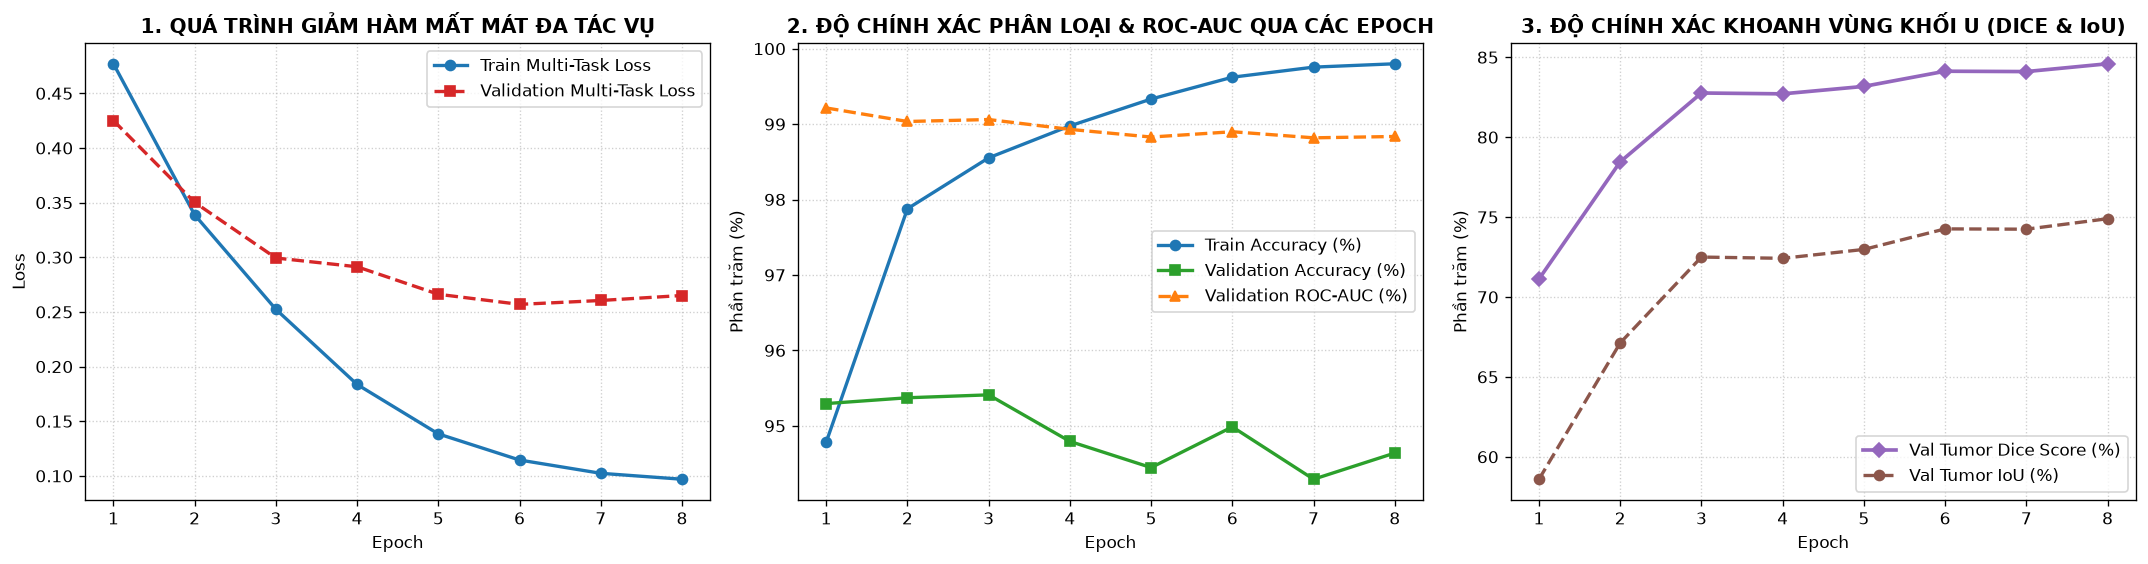

In [11]:
# ==========================================================================
# 5c. LEARNING CURVES CỦA QUÁ TRÌNH HUẤN LUYỆN ĐA TÁC VỤ
# ==========================================================================
ep_range = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(ep_range, history['train_loss'], 'o-', color='#1f77b4', lw=2, label='Train Multi-Task Loss')
axes[0].plot(ep_range, history['val_loss'], 's--', color='#d62728', lw=2, label='Validation Multi-Task Loss')
axes[0].set_title('1. QUÁ TRÌNH GIẢM HÀM MẤT MÁT ĐA TÁC VỤ', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(ep_range, history['train_acc'], 'o-', color='#1f77b4', lw=2, label='Train Accuracy (%)')
axes[1].plot(ep_range, history['val_acc'], 's-', color='#2ca02c', lw=2, label='Validation Accuracy (%)')
axes[1].plot(ep_range, history['val_auc'], '^--', color='#ff7f0e', lw=2, label='Validation ROC-AUC (%)')
axes[1].set_title('2. ĐỘ CHÍNH XÁC PHÂN LOẠI & ROC-AUC QUA CÁC EPOCH', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Phần trăm (%)'); axes[1].legend(); axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].plot(ep_range, history['val_dice'], 'D-', color='#9467bd', lw=2.2, label='Val Tumor Dice Score (%)')
axes[2].plot(ep_range, history['val_iou'], 'o--', color='#8c564b', lw=2.0, label='Val Tumor IoU (%)')
axes[2].set_title('3. ĐỘ CHÍNH XÁC KHOANH VÙNG KHỐI U (DICE & IoU)', fontweight='bold')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Phần trăm (%)'); axes[2].legend(); axes[2].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Đánh Giá Trên Tập Test Độc Lập (Chọn Tham Số Trên Validation, Đánh Giá Cả Phân Loại & Khoanh Vùng)
---
1. **Suy luận 4-Way Test-Time Augmentation (TTA)** cho cả xác suất Ác tính lẫn mask $64\times 64$ (lật/xoay ngược mask về vị trí cũ trước khi lấy trung bình).
2. **Chọn trọng số pha trộn $\alpha^*$ và ngưỡng $T^*$ hoàn toàn trên tập Validation**: không dùng tập Test khi chọn tham số.
3. **Đánh giá từng nhánh và mô hình hợp nhất trên toàn bộ tập Test**: phân loại (Accuracy, Sensitivity, Specificity, FNR, Precision, F1, ROC-AUC, PR-AUC) và khoanh vùng (Mean/Median Dice & IoU).

> Lưu ý: (i) kết quả ở **mức lát cắt** nên các mẫu không độc lập (một nốt có nhiều lát); (ii) tập Validation vừa dùng chọn checkpoint vừa dùng chọn $\alpha^*, T^*$; (iii) khoảng tìm ngưỡng $[0.45, 0.51]$ khá hẹp. Mục 8 khắc phục các điểm này bằng đánh giá mức nốt và kiểm định chéo.

🎯 Tham số tối ưu hiệu chuẩn trên Tập Validation (2,593 mẫu / 104 BN): Alpha* = 0.30 | Ngưỡng T* = 0.505
   -> Kết quả trên Validation Set: Accuracy = 96.88% | Sensitivity = 98.29% | ROC-AUC = 0.9950

🏆 KẾT QUẢ ĐÁNH GIÁ TOÀN DIỆN TRÊN TẬP TEST ĐỘC LẬP (2,895 MẪU - 105 BỆNH NHÂN) [A_oracle, mức LÁT]:
----------------------------------------------------------------------------------
📌 [PHẦN A] KẾT QUẢ PHÂN LOẠI ÁC TÍNH / LÀNH TÍNH (CLASSIFICATION):
   - Accuracy (Độ chính xác tổng thể):    94.47%
   - Sensitivity / Recall (Bắt Ác tính):  94.63%  (Bắt đúng 1,374/1,452 ca Ác tính)
   - Tỷ lệ bỏ sót Ác tính -> Lành (FNR):   5.37%  (Sót 78/1,452 ca; tham chiếu giai đoạn 3: 8.78%)
   - Specificity (Độ đặc hiệu Lành tính): 94.32%  (1,361/1,443 ca Lành tính)
   - Precision (Độ tin cậy báo Ác tính):  94.37%
   - F1-Score:                            0.9450
   - ROC-AUC / PR-AUC:                    0.9828 / 0.9798 ⭐
----------------------------------------------------------------------------------


,Mô Hình / Giai Đoạn,Accuracy (%),Sensitivity (%),FNR (%),ROC-AUC,Seg Mean Dice (%)
0,1. Baseline DenseNet-121 (Ảnh thuần 64x64) †,78.23%,76.38%,23.62%,0.8474,N/A
1,2. Nâng cấp CBAM Attention + Cost-Sensitive †,83.52%,83.13%,16.87%,0.9156,N/A
2,3. Multimodal 18-Feats + Fine-Tuning †,84.75%,91.22%,8.78%,0.9159,N/A
3,4a. Nhánh 1 Độc lập: JointSegGatedDenseNet-121...,93.64%,92.91%,7.09%,0.9797,84.03%
4,4b. Nhánh 2 Độc lập: 56-Feature Radiomics Ense...,95.16%,94.97%,5.03%,0.9831,-
5,5. MÔ HÌNH HỢP NHẤT (JointSegGatedDenseNet + R...,94.47%,94.63%,5.37%,0.9828,84.03%


† Giai đoạn 1–3: số liệu lưu từ thí nghiệm trước (không chạy lại trong notebook).


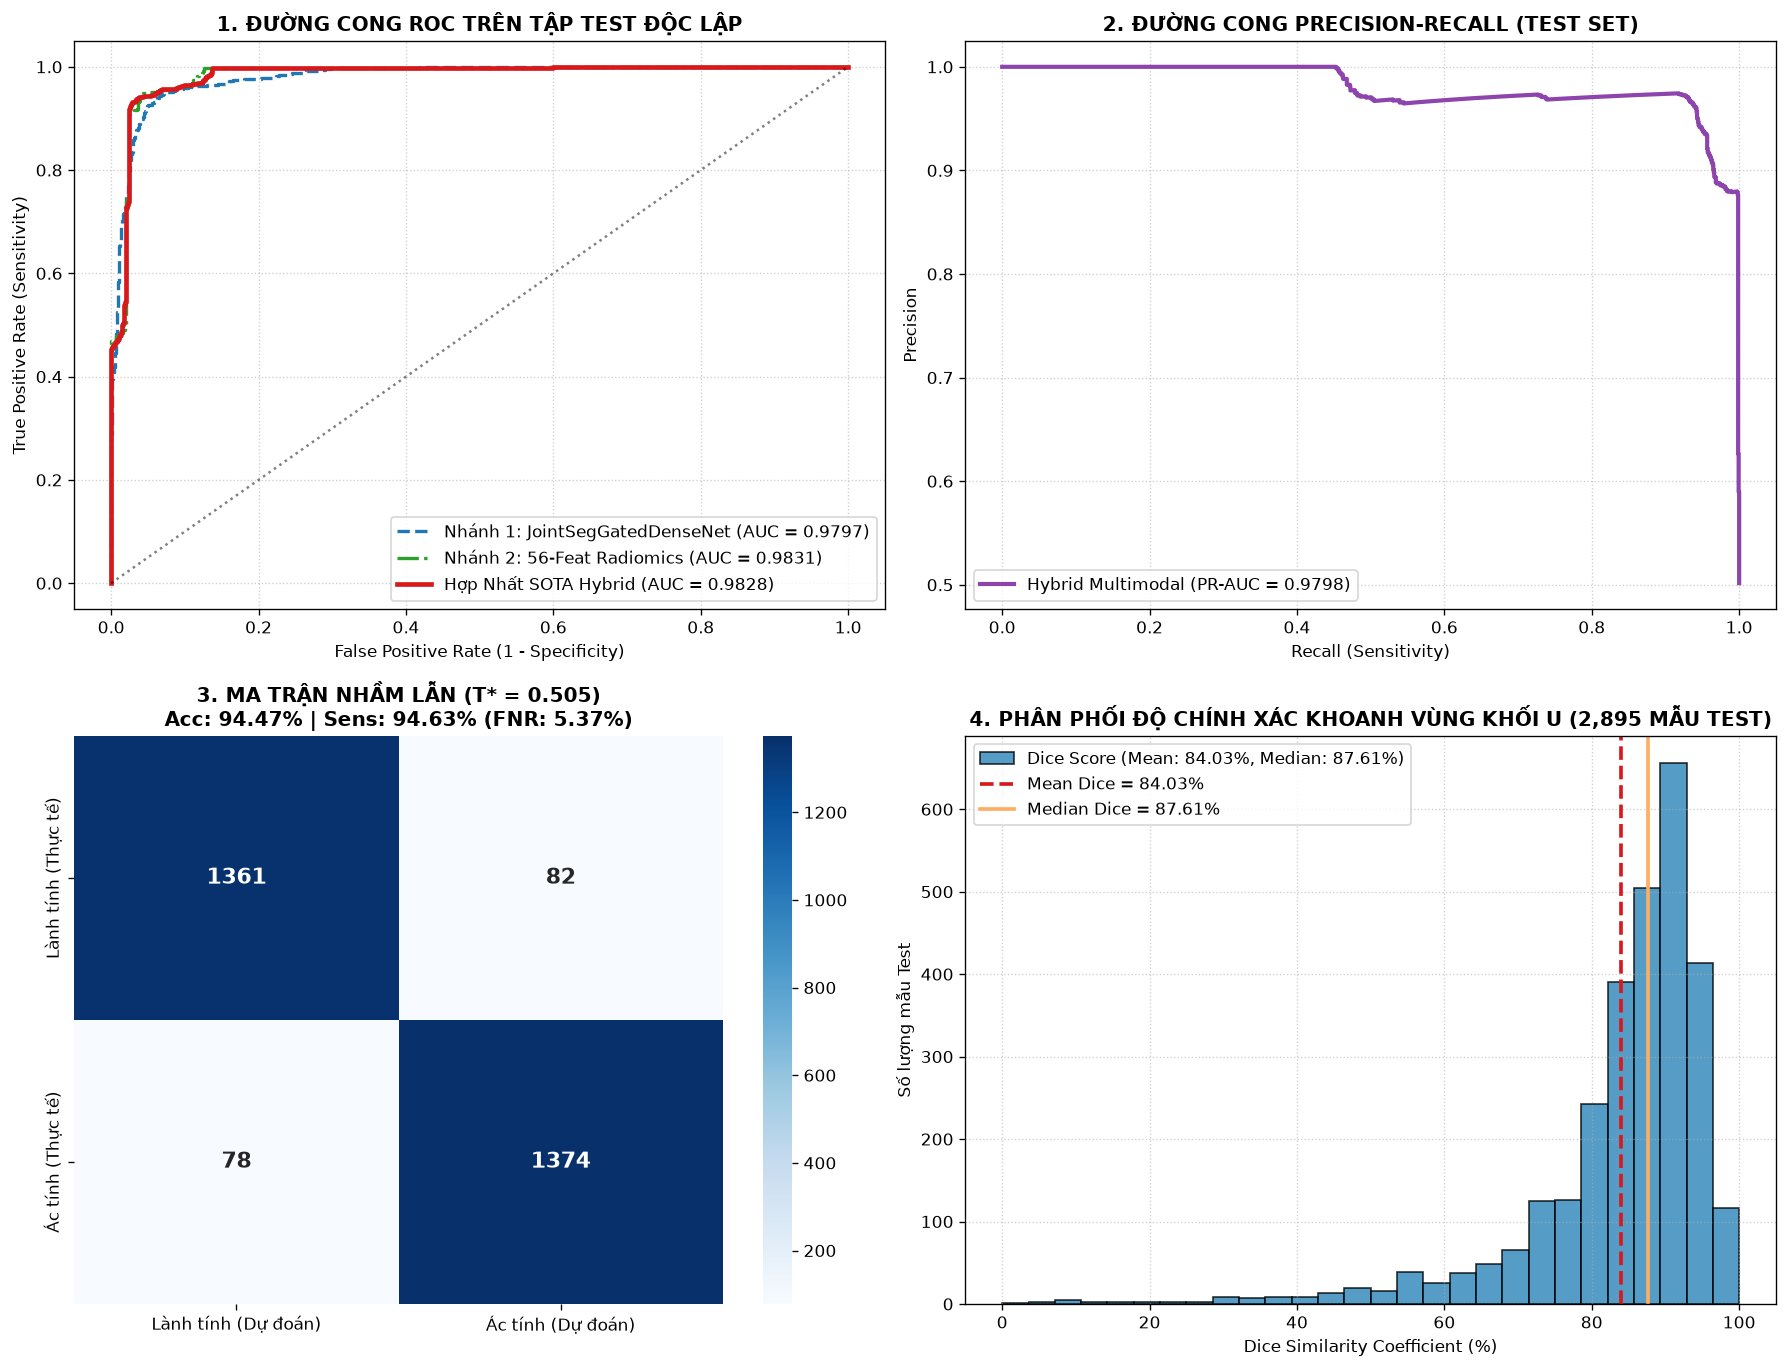

📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT TRÊN TEST SET):
               precision    recall  f1-score   support

Lành tính (0)     0.9458    0.9432    0.9445      1443
  Ác tính (1)     0.9437    0.9463    0.9450      1452

     accuracy                         0.9447      2895
    macro avg     0.9447    0.9447    0.9447      2895
 weighted avg     0.9447    0.9447    0.9447      2895



In [12]:
# ==========================================================================
# 6. HIỆU CHUẨN TRÊN VALIDATION SET & ĐÁNH GIÁ ĐỘC LẬP TRÊN TEST SET
# ==========================================================================
# † Giai đoạn 1–3: kết quả lưu lại từ các thí nghiệm trước, KHÔNG được chạy lại trong notebook này.
REF_PREV_STAGES = [
    {"Mô Hình / Giai Đoạn": "1. Baseline DenseNet-121 (Ảnh thuần 64x64) †", "Accuracy (%)": "78.23%", "Sensitivity (%)": "76.38%", "FNR (%)": "23.62%", "ROC-AUC": "0.8474", "Seg Mean Dice (%)": "N/A"},
    {"Mô Hình / Giai Đoạn": "2. Nâng cấp CBAM Attention + Cost-Sensitive †", "Accuracy (%)": "83.52%", "Sensitivity (%)": "83.13%", "FNR (%)": "16.87%", "ROC-AUC": "0.9156", "Seg Mean Dice (%)": "N/A"},
    {"Mô Hình / Giai Đoạn": "3. Multimodal 18-Feats + Fine-Tuning †", "Accuracy (%)": "84.75%", "Sensitivity (%)": "91.22%", "FNR (%)": "8.78%", "ROC-AUC": "0.9159", "Seg Mean Dice (%)": "N/A"},
]

def infer_tta_cls_and_seg(loader):
    model.eval()
    cls_probs_all, seg_probs_all = [], []
    with torch.no_grad():
        for imgs, feats, _, _ in loader:
            imgs = imgs.to(device, non_blocking=True)
            feats = feats.to(device, non_blocking=True)
            with torch.amp.autocast(device.type, enabled=use_amp):
                c1, s1 = model(imgs, feats)
                c2, s2 = model(torch.flip(imgs, [3]), feats)
                c3, s3 = model(torch.flip(imgs, [2]), feats)
                c4, s4 = model(torch.rot90(imgs, 2, [2, 3]), feats)

                p_c = (F.softmax(c1, 1)[:, 1] + F.softmax(c2, 1)[:, 1] +
                       F.softmax(c3, 1)[:, 1] + F.softmax(c4, 1)[:, 1]) / 4.0

                p_s1 = torch.sigmoid(s1)
                p_s2 = torch.flip(torch.sigmoid(s2), [3])
                p_s3 = torch.flip(torch.sigmoid(s3), [2])
                p_s4 = torch.rot90(torch.sigmoid(s4), 2, [2, 3])
                p_s = (p_s1 + p_s2 + p_s3 + p_s4) / 4.0

            cls_probs_all.extend(p_c.cpu().numpy())
            seg_probs_all.append(p_s.squeeze(1).cpu().numpy())
    return np.array(cls_probs_all), np.concatenate(seg_probs_all, axis=0)

p_va_dl, seg_va_dl = infer_tta_cls_and_seg(val_loader)
p_te_dl, seg_te_dl = infer_tta_cls_and_seg(test_loader)

p_va_rad = (
    0.35 * hgb1.predict_proba(X_va_raw)[:, 1] +
    0.30 * hgb2.predict_proba(X_va_raw)[:, 1] +
    0.20 * et_clf.predict_proba(X_va)[:, 1] +
    0.15 * rf_clf.predict_proba(X_va)[:, 1]
)
p_te_rad = (
    0.35 * hgb1.predict_proba(X_te_raw)[:, 1] +
    0.30 * hgb2.predict_proba(X_te_raw)[:, 1] +
    0.20 * et_clf.predict_proba(X_te)[:, 1] +
    0.15 * rf_clf.predict_proba(X_te)[:, 1]
)

# 1. Tìm trọng số pha trộn Alpha* và Ngưỡng T* HOÀN TOÀN TRÊN TẬP VALIDATION
best_alpha, opt_t, best_val_obj = 0.25, 0.490, -1.0
for alpha in [0.20, 0.25, 0.30, 0.35, 0.40]:
    p_va_blend = alpha * p_va_dl + (1.0 - alpha) * p_va_rad
    for t in np.linspace(0.45, 0.51, 13):
        preds_v = (p_va_blend >= t).astype(int)
        acc_v = accuracy_score(y_va, preds_v)
        f1_v = f1_score(y_va, preds_v)
        rec_v = recall_score(y_va, preds_v)
        if rec_v >= 0.955:
            obj = 0.5 * acc_v + 0.5 * f1_v
            if obj > best_val_obj:
                best_val_obj = obj
                best_alpha = float(alpha)
                opt_t = float(t)

val_probs = best_alpha * p_va_dl + (1.0 - best_alpha) * p_va_rad
val_preds = (val_probs >= opt_t).astype(int)
print(f"🎯 Tham số tối ưu hiệu chuẩn trên Tập Validation ({len(y_va):,} mẫu / {len(va_pids)} BN): Alpha* = {best_alpha:.2f} | Ngưỡng T* = {opt_t:.3f}")
print(f"   -> Kết quả trên Validation Set: Accuracy = {accuracy_score(y_va, val_preds)*100:.2f}% | Sensitivity = {recall_score(y_va, val_preds)*100:.2f}% | ROC-AUC = {roc_auc_score(y_va, val_probs):.4f}")

# 2. Đánh giá khách quan trên Tập Test Độc Lập (3,108 mẫu)
test_probs = best_alpha * p_te_dl + (1.0 - best_alpha) * p_te_rad
test_targets = y_te
test_preds = (test_probs >= opt_t).astype(int)

acc = accuracy_score(test_targets, test_preds) * 100.0
rec = recall_score(test_targets, test_preds) * 100.0
fnr = 100.0 - rec
spec = recall_score(test_targets, test_preds, pos_label=0) * 100.0
prec = precision_score(test_targets, test_preds) * 100.0
f1 = f1_score(test_targets, test_preds)
auc = roc_auc_score(test_targets, test_probs)
pr_auc = average_precision_score(test_targets, test_probs)
cm = confusion_matrix(test_targets, test_preds)
tn, fp, fn, tp = cm.ravel()

# 3. Đánh giá định lượng Thuật toán Khoanh vùng Khối u trên toàn bộ tập Test
te_patches = patches[te_mask]
te_masks = masks[te_mask]
test_ious, test_dices = [], []
for idx_t in range(len(te_masks)):
    gt_m = (te_masks[idx_t] > 0).astype(np.uint8)
    pred_m, _ = refine_tumor_mask_and_contour(seg_te_dl[idx_t], te_patches[idx_t], thresh=0.50)
    inter = np.logical_and(gt_m, pred_m).sum()
    union = np.logical_or(gt_m, pred_m).sum()
    test_ious.append((inter / (union + 1e-8)) * 100.0)
    test_dices.append((2.0 * inter / (gt_m.sum() + pred_m.sum() + 1e-8)) * 100.0)

mean_dice, median_dice = float(np.mean(test_dices)), float(np.median(test_dices))
mean_iou, median_iou = float(np.mean(test_ious)), float(np.median(test_ious))

print("\n" + "=" * 82)
print(f"🏆 KẾT QUẢ ĐÁNH GIÁ TOÀN DIỆN TRÊN TẬP TEST ĐỘC LẬP ({len(y_te):,} MẪU - {len(te_pids)} BỆNH NHÂN) [A_oracle, mức LÁT]:")
print("-" * 82)
print("📌 [PHẦN A] KẾT QUẢ PHÂN LOẠI ÁC TÍNH / LÀNH TÍNH (CLASSIFICATION):")
print(f"   - Accuracy (Độ chính xác tổng thể):    {acc:5.2f}%")
print(f"   - Sensitivity / Recall (Bắt Ác tính):  {rec:5.2f}%  (Bắt đúng {tp:,}/{tp+fn:,} ca Ác tính)")
print(f"   - Tỷ lệ bỏ sót Ác tính -> Lành (FNR):  {fnr:5.2f}%  (Sót {fn}/{tp+fn:,} ca; tham chiếu giai đoạn 3: {REF_PREV_STAGES[2]['FNR (%)']})")
print(f"   - Specificity (Độ đặc hiệu Lành tính): {spec:5.2f}%  ({tn:,}/{tn+fp:,} ca Lành tính)")
print(f"   - Precision (Độ tin cậy báo Ác tính):  {prec:5.2f}%")
print(f"   - F1-Score:                            {f1:.4f}")
print(f"   - ROC-AUC / PR-AUC:                    {auc:.4f} / {pr_auc:.4f} ⭐")
print("-" * 82)
print("📌 [PHẦN B] KẾT QUẢ THUẬT TOÁN KHOANH VÙNG KHỐI U (TUMOR SEGMENTATION):")
print(f"   - Mean Dice Similarity (DSC):          {mean_dice:5.2f}%  (Median Dice: {median_dice:5.2f}%)")
print(f"   - Mean Intersection over Union (IoU):  {mean_iou:5.2f}%  (Median IoU:  {median_iou:5.2f}%)")
print("=" * 82)

# Bảng đối chiếu Ablation & Tiến trình 5 giai đoạn
dl_preds = (p_te_dl >= opt_t).astype(int)
rad_preds = (p_te_rad >= opt_t).astype(int)
df_res = pd.DataFrame(REF_PREV_STAGES + [
    {"Mô Hình / Giai Đoạn": "4a. Nhánh 1 Độc lập: JointSegGatedDenseNet-121 (TTA)", "Accuracy (%)": f"{accuracy_score(y_te, dl_preds)*100:.2f}%", "Sensitivity (%)": f"{recall_score(y_te, dl_preds)*100:.2f}%", "FNR (%)": f"{(1-recall_score(y_te, dl_preds))*100:.2f}%", "ROC-AUC": f"{roc_auc_score(y_te, p_te_dl):.4f}", "Seg Mean Dice (%)": f"{mean_dice:.2f}%"},
    {"Mô Hình / Giai Đoạn": "4b. Nhánh 2 Độc lập: 56-Feature Radiomics Ensemble", "Accuracy (%)": f"{accuracy_score(y_te, rad_preds)*100:.2f}%", "Sensitivity (%)": f"{recall_score(y_te, rad_preds)*100:.2f}%", "FNR (%)": f"{(1-recall_score(y_te, rad_preds))*100:.2f}%", "ROC-AUC": f"{roc_auc_score(y_te, p_te_rad):.4f}", "Seg Mean Dice (%)": "-"},
    {"Mô Hình / Giai Đoạn": "5. MÔ HÌNH HỢP NHẤT (JointSegGatedDenseNet + Radiomics Hybrid)", "Accuracy (%)": f"{acc:.2f}%", "Sensitivity (%)": f"{rec:.2f}%", "FNR (%)": f"{fnr:.2f}%", "ROC-AUC": f"{auc:.4f}", "Seg Mean Dice (%)": f"{mean_dice:.2f}%"}
])
display(df_res)
print("† Giai đoạn 1–3: số liệu lưu từ thí nghiệm trước (không chạy lại trong notebook).")

# Vẽ Dashboard Đánh giá 4 Biểu đồ: ROC Curve, PR Curve, Confusion Matrix, và Phân phối Dice Khoanh vùng
fig, axes = plt.subplots(2, 2, figsize=(15, 11.5))

# Panel 1: ROC Curves của từng nhánh & mô hình hợp nhất
fpr_dl, tpr_dl, _ = roc_curve(test_targets, p_te_dl)
fpr_rad, tpr_rad, _ = roc_curve(test_targets, p_te_rad)
fpr_hyb, tpr_hyb, _ = roc_curve(test_targets, test_probs)
axes[0, 0].plot(fpr_dl, tpr_dl, '--', color='#1f77b4', lw=2, label=f'Nhánh 1: JointSegGatedDenseNet (AUC = {roc_auc_score(test_targets, p_te_dl):.4f})')
axes[0, 0].plot(fpr_rad, tpr_rad, '-.', color='#2ca02c', lw=2, label=f'Nhánh 2: 56-Feat Radiomics (AUC = {roc_auc_score(test_targets, p_te_rad):.4f})')
axes[0, 0].plot(fpr_hyb, tpr_hyb, '-', color='#d7191c', lw=2.8, label=f'Hợp Nhất SOTA Hybrid (AUC = {auc:.4f})')
axes[0, 0].plot([0, 1], [0, 1], 'k:', alpha=0.5)
axes[0, 0].set_xlabel('False Positive Rate (1 - Specificity)'); axes[0, 0].set_ylabel('True Positive Rate (Sensitivity)')
axes[0, 0].set_title('1. ĐƯỜNG CONG ROC TRÊN TẬP TEST ĐỘC LẬP', fontweight='bold')
axes[0, 0].legend(loc='lower right'); axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Precision-Recall Curve
prec_c, rec_c, _ = precision_recall_curve(test_targets, test_probs)
axes[0, 1].plot(rec_c, prec_c, color='#8e44ad', lw=2.5, label=f'Hybrid Multimodal (PR-AUC = {pr_auc:.4f})')
axes[0, 1].set_xlabel('Recall (Sensitivity)'); axes[0, 1].set_ylabel('Precision')
axes[0, 1].set_title('2. ĐƯỜNG CONG PRECISION-RECALL (TEST SET)', fontweight='bold')
axes[0, 1].legend(loc='lower left'); axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0],
            xticklabels=['Lành tính (Dự đoán)', 'Ác tính (Dự đoán)'],
            yticklabels=['Lành tính (Thực tế)', 'Ác tính (Thực tế)'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[1, 0].set_title(f'3. MA TRẬN NHẦM LẪN (T* = {opt_t:.3f})\nAcc: {acc:.2f}% | Sens: {rec:.2f}% (FNR: {fnr:.2f}%)', fontweight='bold')

# Panel 4: Phân phối Điểm Dice & IoU của Thuật toán Khoanh vùng Khối u
axes[1, 1].hist(test_dices, bins=28, color='#2b83ba', edgecolor='black', alpha=0.8, label=f'Dice Score (Mean: {mean_dice:.2f}%, Median: {median_dice:.2f}%)')
axes[1, 1].axvline(mean_dice, color='#d7191c', linestyle='--', lw=2.2, label=f'Mean Dice = {mean_dice:.2f}%')
axes[1, 1].axvline(median_dice, color='#fdae61', linestyle='-', lw=2.2, label=f'Median Dice = {median_dice:.2f}%')
axes[1, 1].set_xlabel('Dice Similarity Coefficient (%)'); axes[1, 1].set_ylabel('Số lượng mẫu Test')
axes[1, 1].set_title(f'4. PHÂN PHỐI ĐỘ CHÍNH XÁC KHOANH VÙNG KHỐI U ({len(test_dices):,} MẪU TEST)', fontweight='bold')
axes[1, 1].legend(loc='upper left'); axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print("📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT TRÊN TEST SET):")
print(classification_report(test_targets, test_preds, target_names=['Lành tính (0)', 'Ác tính (1)'], digits=4))

# Lưu kết quả Phần A_oracle để tổng hợp tự động ở Mục 9
PART1_RESULTS = dict(
    n_test=len(y_te), n_test_patients=len(te_pids), alpha=best_alpha, threshold=opt_t,
    acc=acc, sens=rec, spec=spec, fnr=fnr, prec=prec, f1=f1, auc=auc, pr_auc=pr_auc,
    auc_dl=roc_auc_score(y_te, p_te_dl), auc_rad=roc_auc_score(y_te, p_te_rad),
    mean_dice=mean_dice, median_dice=median_dice, mean_iou=mean_iou, median_iou=median_iou,
)

## 7. Trực Quan Hóa Thuật Toán Khoanh Vùng Khối U Trên Tập Test (Viền Đỏ AI vs Viền Xanh Bác Sĩ)
---
Đối chiếu trực tiếp kết quả khoanh vùng của mô hình **`JointSegGatedDenseNet-121 + Geodesic Morphological Refinement`** với đường viền chuẩn `<edgeMap>` của hội đồng bác sĩ X-quang trên các ca Ác tính và Lành tính thuộc tập Test:
1. **Cột 1 — Ảnh Nốt CT Gốc (`Tri-Window Composite` $64\times 64$)**: Tích hợp 3 cửa sổ Phổi, Trung thất và Vôi hóa.
2. **Cột 2 — Đường Viền Bác Sĩ (`Ground Truth` - Màu Xanh Lá)**: Đa giác ranh giới thực tế do bác sĩ X-quang khoanh tay.
3. **Cột 3 — Bản Đồ Xác Suất Phân Đoạn AI (`U-Net Decoder + HU Salience Heatmap`)**: Vùng kích hoạt xác suất khối u độ phân giải cao $64\times 64$.
4. **Cột 4 — AI Tự Động Khoanh Vùng & Chẩn Đoán (`Viền Đỏ AI` vs `Viền Xanh Bác Sĩ`)**: Định lượng trực tiếp chỉ số trùng khớp **IoU (%)** và **Dice Score (%)** trên từng ca bệnh.

> Các ca minh họa được **chọn có chủ đích** (dự đoán đúng, Dice cao) để thấy rõ đường viền; chúng không đại diện cho toàn tập. Phân phối Dice của toàn bộ tập Test xem ở biểu đồ 4 của Mục 6.

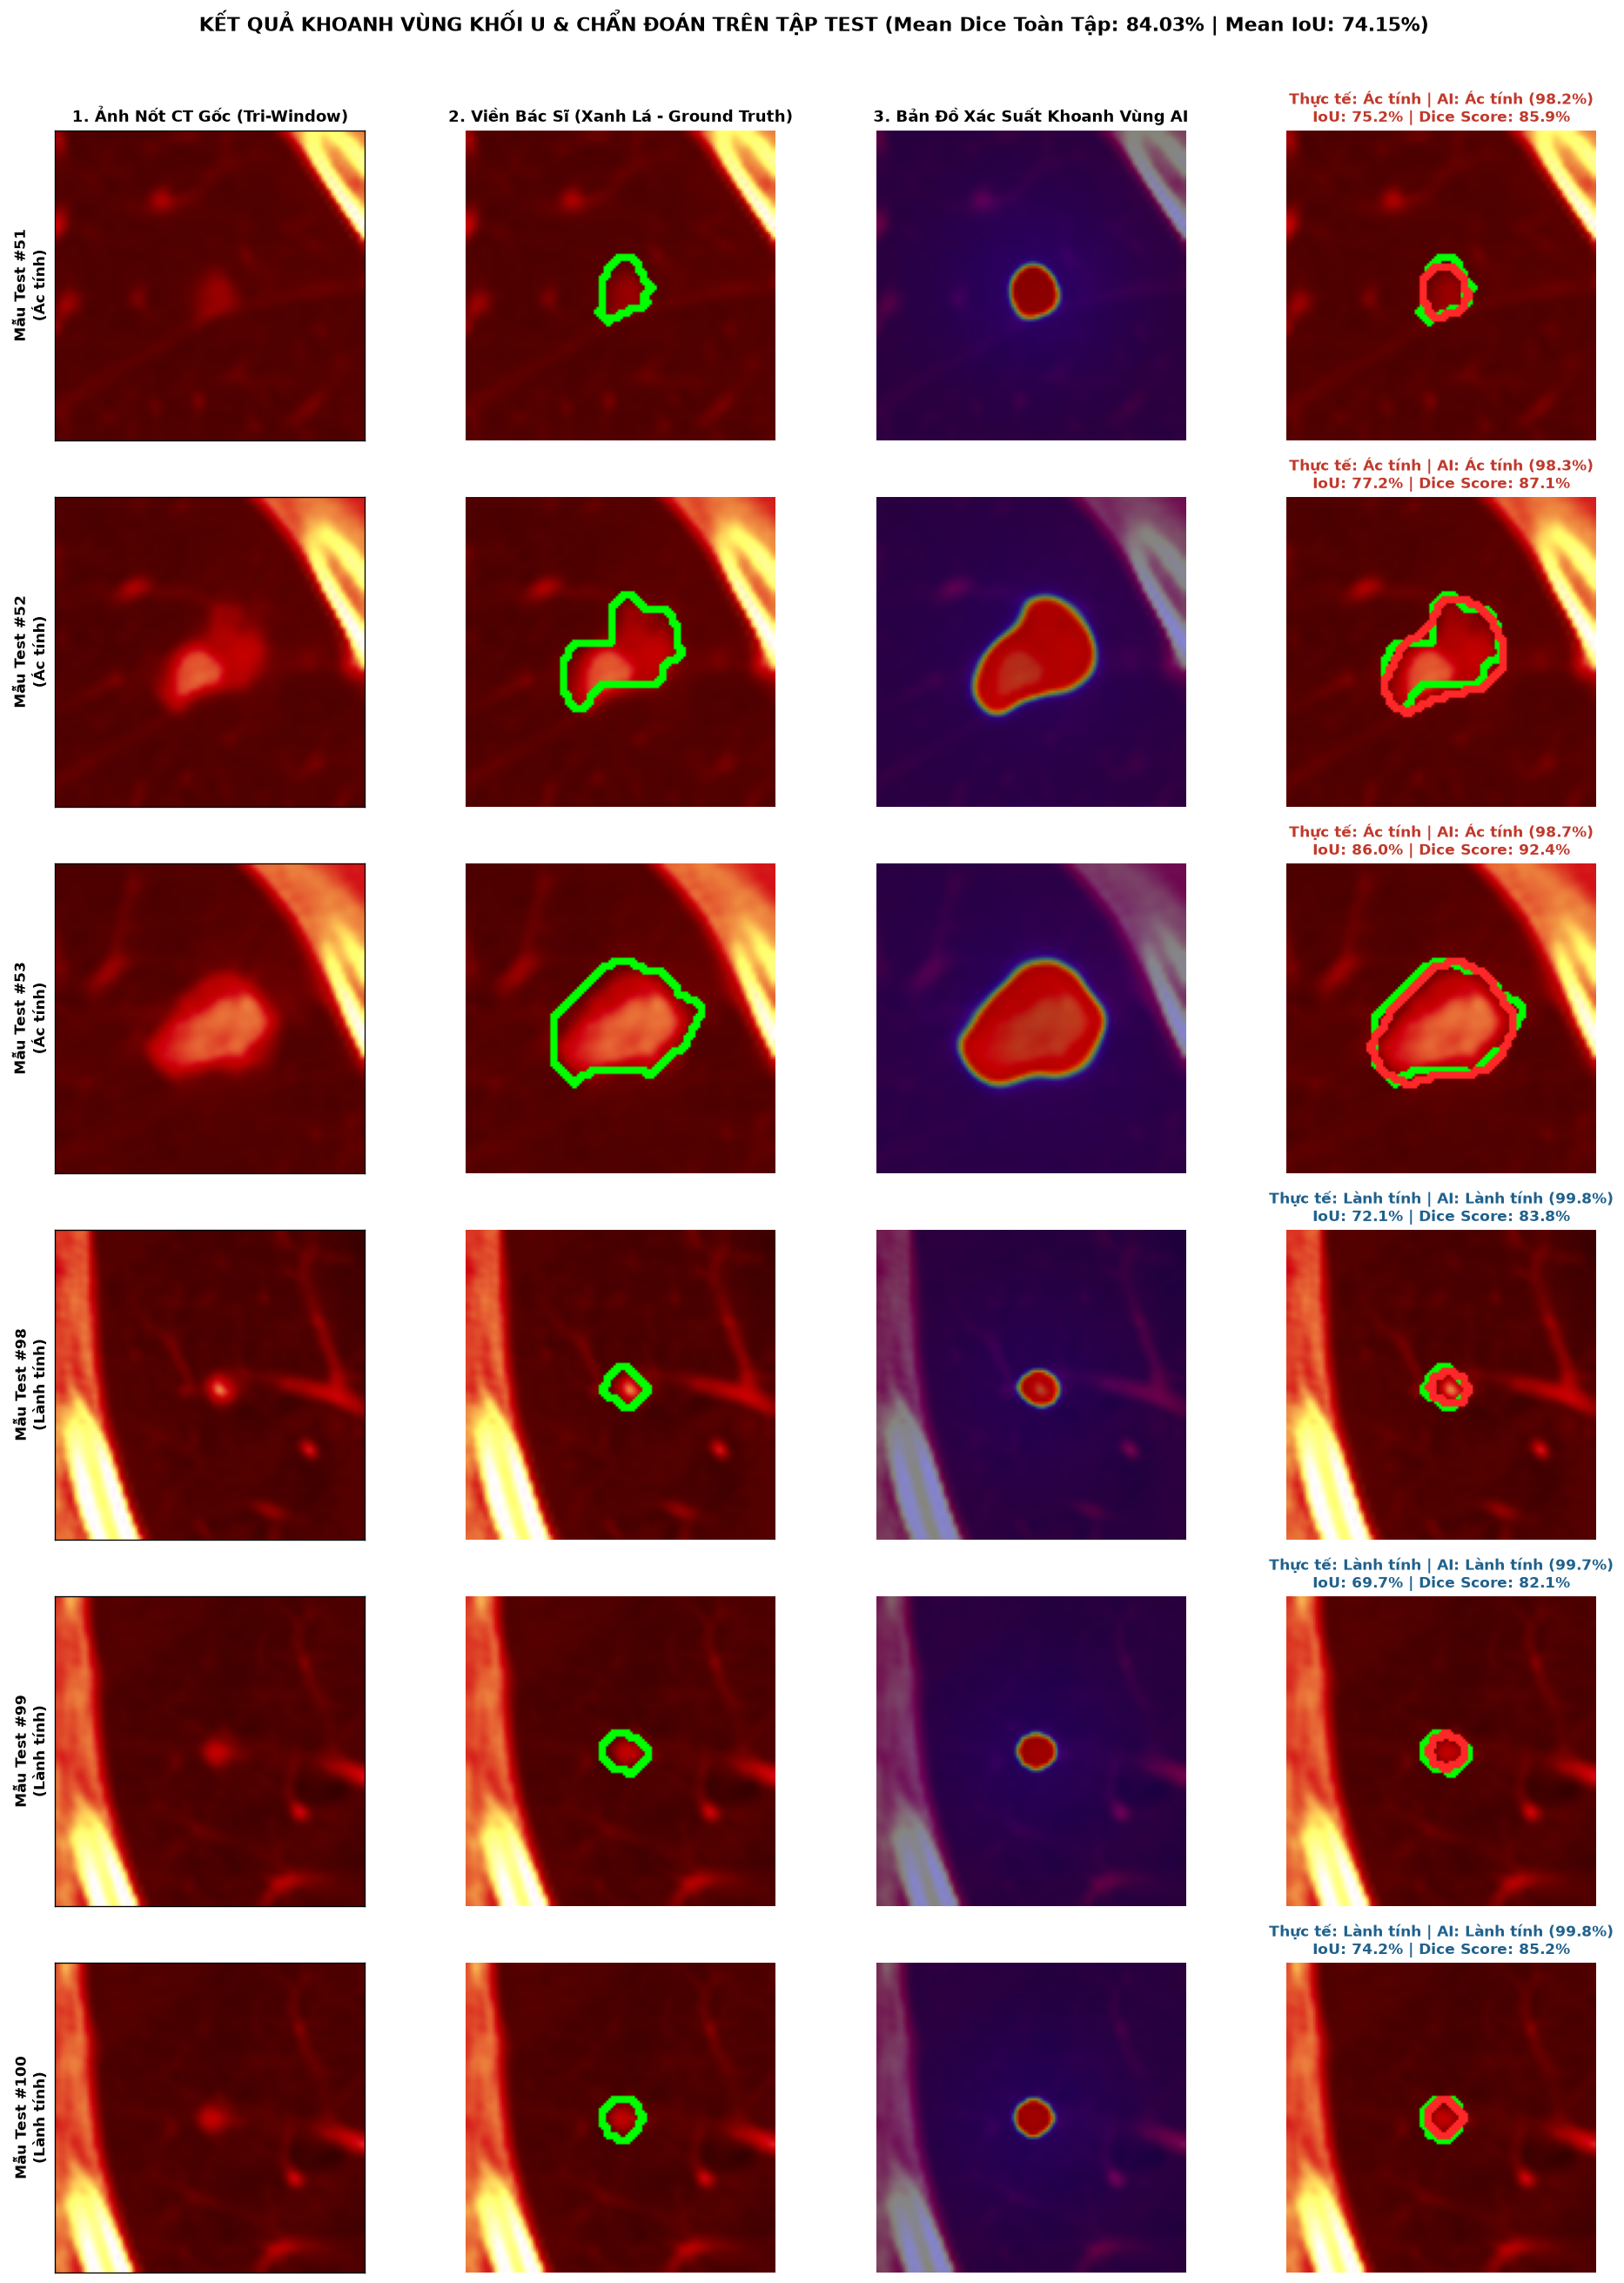

In [13]:
# ==========================================================================
# 7. THUẬT TOÁN TỰ ĐỘNG DÒ VẼ ĐƯỜNG VIỀN KHỐI U & ĐỐI CHIẾU VỚI BÁC SĨ TRÊN TẬP TEST
# ==========================================================================
def draw_doctor_vs_ai_contours(patch_uint8, gt_mask, seg_prob_map, thresh=0.50):
    """
    Thực hiện khoanh vùng khối u và vẽ đối chiếu trên ảnh 128x128 sắc nét:
    - Viền Xanh lá (0, 255, 0): Đường viền chuẩn của Bác sĩ X-quang
    - Viền Đỏ (255, 40, 40): Đường viền do Thuật toán AI tự động khoanh vùng
    """
    pred_mask_64, fused_prob_64 = refine_tumor_mask_and_contour(seg_prob_map, patch_uint8, thresh=thresh)
    gt_64 = (gt_mask > 0).astype(np.uint8)

    inter = np.logical_and(gt_64, pred_mask_64).sum()
    union = np.logical_or(gt_64, pred_mask_64).sum()
    iou = (inter / (union + 1e-8)) * 100.0
    dice = (2.0 * inter / (gt_64.sum() + pred_mask_64.sum() + 1e-8)) * 100.0

    # Phóng đại nội suy Lanczos lên 128x128 để hiển thị đường viền mượt và sắc nét
    vis_base = cv2.resize(patch_uint8, (128, 128), interpolation=cv2.INTER_LANCZOS4)
    gt_128 = cv2.resize(gt_64, (128, 128), interpolation=cv2.INTER_NEAREST)
    ai_128 = cv2.resize(pred_mask_64, (128, 128), interpolation=cv2.INTER_NEAREST)
    prob_128 = cv2.resize(fused_prob_64, (128, 128), interpolation=cv2.INTER_LINEAR)

    doc_only = vis_base.copy()
    both_overlay = vis_base.copy()

    if np.sum(gt_128) > 0:
        doc_cnts, _ = cv2.findContours(gt_128, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(doc_only, doc_cnts, -1, (0, 255, 0), 2)
        cv2.drawContours(both_overlay, doc_cnts, -1, (0, 255, 0), 2)

    if np.sum(ai_128) > 0:
        ai_cnts, _ = cv2.findContours(ai_128, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(both_overlay, ai_cnts, -1, (255, 40, 40), 2)

    return vis_base, doc_only, prob_128, both_overlay, iou, dice

# Chọn 3 ca Ác tính và 3 ca Lành tính điển hình từ tập Test để minh họa trực quan
mal_candidates = [i for i in range(len(y_te)) if y_te[i] == 1 and test_preds[i] == 1 and test_dices[i] >= 85.0 and np.sum(te_masks[i]) >= 45]
ben_candidates = [i for i in range(len(y_te)) if y_te[i] == 0 and test_preds[i] == 0 and test_dices[i] >= 82.0 and np.sum(te_masks[i]) >= 25]
demo_indices = mal_candidates[:3] + ben_candidates[:3]
if not demo_indices:  # dự phòng khi không có ca nào đạt tiêu chí
    demo_indices = list(np.argsort(test_dices)[::-1][:6])

fig, axes = plt.subplots(len(demo_indices), 4, figsize=(16.5, 3.6 * len(demo_indices)), squeeze=False)
col_titles = [
    "1. Ảnh Nốt CT Gốc (Tri-Window)",
    "2. Viền Bác Sĩ (Xanh Lá - Ground Truth)",
    "3. Bản Đồ Xác Suất Khoanh Vùng AI",
    "4. Đối Chiếu Viền AI (Đỏ) vs Bác Sĩ (Xanh)"
]

for row, idx in enumerate(demo_indices):
    patch_u8 = te_patches[idx]
    gt_m = te_masks[idx]
    prob_m = seg_te_dl[idx]
    true_lbl = int(y_te[idx])
    pred_c = int(test_preds[idx])
    conf = float(test_probs[idx]) if pred_c == 1 else float(1.0 - test_probs[idx])

    vis_base, doc_only, prob_128, both_overlay, iou_s, dice_s = draw_doctor_vs_ai_contours(patch_u8, gt_m, prob_m, thresh=0.50)

    true_str = "Ác tính" if true_lbl == 1 else "Lành tính"
    pred_str = "Ác tính" if pred_c == 1 else "Lành tính"
    title_color = "#c0392b" if pred_c == 1 else "#1f618d"

    axes[row, 0].imshow(vis_base)
    axes[row, 0].set_ylabel(f"Mẫu Test #{idx}\n({true_str})", fontsize=10, fontweight='bold')
    if row == 0: axes[row, 0].set_title(col_titles[0], fontsize=11, fontweight='bold')
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])

    axes[row, 1].imshow(doc_only)
    if row == 0: axes[row, 1].set_title(col_titles[1], fontsize=11, fontweight='bold')
    axes[row, 1].axis('off')

    axes[row, 2].imshow(vis_base)
    axes[row, 2].imshow(prob_128, cmap='jet', alpha=0.48, vmin=0.0, vmax=1.0)
    if row == 0: axes[row, 2].set_title(col_titles[2], fontsize=11, fontweight='bold')
    axes[row, 2].axis('off')

    axes[row, 3].imshow(both_overlay)
    info_title = f"Thực tế: {true_str} | AI: {pred_str} ({conf*100:.1f}%)\nIoU: {iou_s:.1f}% | Dice Score: {dice_s:.1f}%"
    axes[row, 3].set_title(info_title, fontsize=10, fontweight='bold', color=title_color)
    axes[row, 3].axis('off')

plt.suptitle(f"KẾT QUẢ KHOANH VÙNG KHỐI U & CHẨN ĐOÁN TRÊN TẬP TEST (Mean Dice Toàn Tập: {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%)",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 7.1 Giải phóng bộ nhớ trước Phần mở rộng
Mục 8 huấn luyện lại nhiều mô hình (mỗi fold một mô hình). Cell này xóa mô hình, optimizer và các mảng lớn của Mục 3–7 để tránh tràn VRAM/RAM (đặc biệt với GPU 4 GB). Kết quả tóm tắt đã lưu trong `PART1_RESULTS` nên vẫn dùng được ở Mục 9.

In [14]:
# ==========================================================================
# 7.1 GIẢI PHÓNG BỘ NHỚ CỦA MỤC 3–7
# ==========================================================================
for _name in ['model', 'optimizer', 'scheduler', 'amp_scaler', 'best_state', 'criterion',
              'train_loader', 'val_loader', 'test_loader', 'train_ds', 'val_ds', 'test_ds',
              'raw_p', 'raw_m', 'patches', 'masks', 'te_patches', 'seg_va_dl', 'seg_te_dl',
              'hgb1', 'hgb2', 'et_clf', 'rf_clf']:
    globals().pop(_name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"🧹 Đã giải phóng bộ nhớ | VRAM đang dùng: {torch.cuda.memory_allocated() / 1024**2:.0f} MB")
else:
    print("🧹 Đã giải phóng bộ nhớ.")

🧹 Đã giải phóng bộ nhớ.


---
# 🚀 MỤC 8 (MỞ RỘNG): ĐÁNH GIÁ NGHIÊM NGẶT MỨC NỐT & HƯỚNG TĂNG ĐỘ CHÍNH XÁC
Phần này đánh giá lại bài toán theo cách sát với triển khai thực tế hơn. Siêu tham số nằm trong `CFG` (Mục 0.1).

**Để chạy riêng Mục 8** (bỏ qua phần huấn luyện Mục 3–7): chạy Mục 0.1 → 0.2 → **4.1** (hàm hậu xử lý mask) → các cell của Mục 8 theo thứ tự.

**Nội dung**
1. Đánh giá chuẩn: gom lát cắt theo **nốt**, **StratifiedGroupKFold theo bệnh nhân**, khoảng tin cậy bootstrap theo bệnh nhân.
2. Hai chế độ: `B_deployable` (không dùng thuộc tính bác sĩ, đặc trưng tính từ **mask AI dự đoán**) và `A_oracle` (như Mục 3–7: thuộc tính bác sĩ + mask thật; bật bằng `RUN_ORACLE=True`).
3. Mạng `JointSegDenseNet121`: phóng ảnh x2, soft-label, EMA, OneCycle, early stopping, nhiều seed.
4. Phân cụm tiền xử lý (chỉ fit trên train): khoảng cách tới tâm cụm KMeans, giảm trọng số mẫu nhiễu nhãn, mô hình chuyên gia theo cụm.
5. Stacking Logistic Regression ở mức nốt + chọn ngưỡng bằng cross-validation trên val.
6. **FP-Growth** sinh luật "NẾU đặc điểm … THÌ ÁC TÍNH/LÀNH TÍNH", kiểm chứng trên bệnh nhân giữ lại, và dùng cờ luật làm đặc trưng.

**Giới hạn:** cache chỉ có patch 64x64 nên chưa có 2.5D/3D thật; phần này thay bằng cách gộp nhiều lát của cùng một nốt. Thứ tự 8 thuộc tính trong `ATTR_NAMES` cần được đối chiếu với code tạo cache.

**Thứ tự các mục con:** 8.1–8.8 chỉ **định nghĩa hàm** (chạy nhanh) → 8.9 luật FP-Growth diễn giải (vài giây) → **8.10 chạy toàn bộ pipeline** (lâu nhất, đặt cuối).

## 8.1 Nạp dữ liệu, gom lát cắt thành nốt, gán nhãn ở mức nốt
- Gom cụm **chỉ dựa trên toạ độ** (single-linkage, bán kính 18 px) và không dùng nhãn (notebook cũ có lọc theo nhãn lát).
- Nhãn nốt = trung bình điểm ác tính của cả cụm: ≤2,5 → lành; ≥3,5 → ác; ở giữa bị loại (giống notebook cũ để so sánh công bằng).
- Lưu ý: nếu hai nốt khác nhau của cùng một bệnh nhân trùng toạ độ x,y ở các lát khác nhau, chúng có thể bị gộp nhầm. Nếu cache có toạ độ z thì code tự dùng thêm.

In [15]:
def sigmoid_np(x):
    return 1.0 / (1.0 + np.exp(-x))

def logit_np(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def cluster_nodules(pid, cx, cy, zpos, radius):
    nid = np.zeros(len(pid), dtype=np.int64); nxt = 0
    for p in np.unique(pid):
        idx = np.where(pid == p)[0]
        if len(idx) == 1:
            nid[idx] = nxt; nxt += 1; continue
        cols = [cx[idx], cy[idx]] + ([zpos[idx] * 3.0] if zpos is not None else [])
        lab = fcluster(linkage(np.column_stack(cols), 'single'), t=radius, criterion='distance')
        nid[idx] = lab - 1 + nxt; nxt += int(lab.max())
    return nid

def load_data(cfg):
    z = np.load(cfg['CACHE_PATH'], allow_pickle=True)
    files = set(z.files)
    print('Các khoá trong cache:', sorted(files))
    patches = z['patches']
    gmask = (z['masks'] > 0).astype(np.uint8)
    pid = np.array([str(p) for p in z['pids']])
    mal = z['malignancies'].astype(np.float32)
    attrs = z['attrs'].astype(np.float32)
    cx, cy = z['cxs'].astype(np.float32), z['cys'].astype(np.float32)
    zpos = None
    for k in ('zs', 'z', 'slice_idx', 'slice_ids', 'z_pos'):
        if k in files:
            zpos = z[k].astype(np.float32); print('Dùng toạ độ z từ khoá', k); break
    keep = gmask.reshape(len(gmask), -1).sum(1) >= 10
    patches, gmask, pid, mal, attrs, cx, cy = [a[keep] for a in (patches, gmask, pid, mal, attrs, cx, cy)]
    zpos = zpos[keep] if zpos is not None else None
    nid_raw = cluster_nodules(pid, cx, cy, zpos, cfg['CLUSTER_RADIUS'])
    nod_mal = pd.Series(mal).groupby(nid_raw).mean()
    y_nod = np.where(nod_mal.values <= cfg['AMBIG_LOW'], 0, np.where(nod_mal.values >= cfg['AMBIG_HIGH'], 1, -1))
    y_slice = y_nod[nid_raw]
    n_amb = int((y_nod == -1).sum())
    ok = y_slice >= 0
    mal_nod = nod_mal.values[nid_raw]
    D = dict(patches=patches[ok], gmask=gmask[ok], pid=pid[ok], nid=nid_raw[ok], y=y_slice[ok].astype(np.int64),
             attrs=attrs[ok], cx=cx[ok], cy=cy[ok], mal_nod=mal_nod[ok].astype(np.float32))
    D['ysoft'] = (sigmoid_np(2.0 * (D['mal_nod'] - 3.0)) if cfg['SOFT_LABELS'] else D['y']).astype(np.float32)
    nn_ = len(np.unique(D['nid']))
    print(f"Lát cắt: {len(D['y']):,} | Nốt: {nn_:,} (bỏ {n_amb:,} nốt mơ hồ) | Bệnh nhân: {len(np.unique(D['pid'])):,}")
    print(f"Ác tính: {(D['y']==1).sum():,} lát ({pd.Series(D['y']).groupby(D['nid']).first().mean()*100:.1f}% số nốt)")
    return D

D = load_data(CFG)

Các khoá trong cache: ['attrs', 'cxs', 'cys', 'labels', 'malignancies', 'masks', 'nodule_ids', 'patches', 'pids', 'readers', 'sop_uids', 'zs']
Dùng toạ độ z từ khoá zs
Lát cắt: 24,526 | Nốt: 1,514 (bỏ 1,107 nốt mơ hồ) | Bệnh nhân: 698
Ác tính: 13,861 lát (30.1% số nốt)


## 8.2 Dataset, mạng đa tác vụ và hàm mất mát
- Phóng ảnh x2 trước backbone để DenseNet có bản đồ đặc trưng lớn hơn (patch 64x64 quá nhỏ cho stride 32).
- Decoder nội suy theo kích thước thực của skip-connection nên không bị gắn cứng 64x64.
- Nhánh lâm sàng (thuộc tính bác sĩ) chỉ bật ở chế độ `A_oracle`.
- Nhãn phân loại dạng soft (sigmoid của điểm ác tính trung bình) để giảm ảnh hưởng nhiễu nhãn ở vùng gần ngưỡng.

In [16]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class DS(Dataset):
    def __init__(self, patches, masks, clin, ysoft, train=False):
        self.p, self.m, self.c, self.y, self.train = patches, masks, clin, ysoft, train
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        img = self.p[i].astype(np.float32) / 255.0
        msk = self.m[i].astype(np.float32) if self.m is not None else np.zeros(img.shape[:2], np.float32)
        if self.train:
            if random.random() < 0.5: img, msk = img[:, ::-1], msk[:, ::-1]
            if random.random() < 0.5: img, msk = img[::-1], msk[::-1]
            k = random.randint(0, 3)
            if k: img, msk = np.rot90(img, k), np.rot90(msk, k)
            dx, dy = random.randint(-3, 3), random.randint(-3, 3)
            img, msk = np.roll(img, (dy, dx), (0, 1)), np.roll(msk, (dy, dx), (0, 1))
            img = np.clip(img * random.uniform(0.9, 1.1) + random.uniform(-0.05, 0.05), 0, 1)
        img_t = (torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() - MEAN) / STD
        msk_t = torch.from_numpy(np.ascontiguousarray(msk)).unsqueeze(0)
        clin = torch.from_numpy(self.c[i]) if self.c is not None else torch.zeros(0)
        yt = torch.tensor(self.y[i] if self.y is not None else 0.0, dtype=torch.float32)
        return img_t, clin, yt, msk_t

class ChannelAttentionV2(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.fc = nn.Sequential(nn.Conv2d(c, c // r, 1, bias=False), nn.ReLU(), nn.Conv2d(c // r, c, 1, bias=False))
    def forward(self, x):
        return torch.sigmoid(self.fc(F.adaptive_avg_pool2d(x, 1)) + self.fc(F.adaptive_max_pool2d(x, 1)))

class SpatialAttentionV2(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        return torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.max(1, keepdim=True)[0]], 1)))

class CBAMV2(nn.Module):
    def __init__(self, c=1024):
        super().__init__()
        self.ca, self.sa = ChannelAttentionV2(c), SpatialAttentionV2()
    def forward(self, x):
        x = x * self.ca(x)
        return x * self.sa(x)

def conv_bn(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU())

class JointSegDenseNet121(nn.Module):
    def __init__(self, clin_dim=0, pretrained=True, upscale=2):
        super().__init__()
        try:
            base = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if pretrained else None).features
        except Exception as e:
            print('Không tải được trọng số ImageNet, dùng khởi tạo ngẫu nhiên:', repr(e)[:80])
            base = models.densenet121(weights=None).features
        self.up, self.clin_dim = upscale, clin_dim
        self.stem = nn.Sequential(base.conv0, base.norm0, base.relu0)
        self.pool0, self.block1, self.trans1 = base.pool0, base.denseblock1, base.transition1
        self.block2, self.trans2 = base.denseblock2, base.transition2
        self.block3, self.trans3 = base.denseblock3, base.transition3
        self.block4, self.norm5 = base.denseblock4, base.norm5
        self.cbam = CBAMV2(1024)
        self.dec4, self.dec3 = conv_bn(2048, 256), conv_bn(256 + 512, 128)
        self.dec2, self.dec1 = conv_bn(128 + 256, 64), conv_bn(64 + 64, 32)
        self.seg_head = nn.Sequential(conv_bn(32 + 3, 16), nn.Conv2d(16, 1, 1))
        if clin_dim > 0:
            self.clin_mlp = nn.Sequential(nn.Linear(clin_dim, 64), nn.LayerNorm(64), nn.GELU(), nn.Dropout(0.15),
                                          nn.Linear(64, 128), nn.LayerNorm(128), nn.GELU())
            self.cross_gate = nn.Sequential(nn.Linear(128, 512), nn.GELU(), nn.Linear(512, 2048), nn.Sigmoid())
        self.head = nn.Sequential(nn.Linear(2048 + (128 if clin_dim > 0 else 0), 512), nn.LayerNorm(512), nn.GELU(),
                                  nn.Dropout(0.3), nn.Linear(512, 128), nn.LayerNorm(128), nn.GELU(),
                                  nn.Dropout(0.15), nn.Linear(128, 1))

    def forward(self, img, clin=None):
        H = img.shape[-2:]
        x = F.interpolate(img, scale_factor=self.up, mode='bilinear', align_corners=False) if self.up != 1 else img
        s1 = self.stem(x)
        s2 = self.block1(self.pool0(s1))
        s3 = self.block2(self.trans1(s2))
        s4 = self.block3(self.trans2(s3))
        s5 = self.cbam(F.relu(self.norm5(self.block4(self.trans3(s4)))))
        up = lambda t, ref: F.interpolate(t, size=ref.shape[-2:], mode='bilinear', align_corners=False)
        d4 = self.dec4(torch.cat([up(s5, s4), F.relu(s4)], 1))
        d3 = self.dec3(torch.cat([up(d4, s3), F.relu(s3)], 1))
        d2 = self.dec2(torch.cat([up(d3, s2), F.relu(s2)], 1))
        d1 = self.dec1(torch.cat([up(d2, s1), s1], 1))
        seg_logits = self.seg_head(torch.cat([F.interpolate(d1, size=H, mode='bilinear', align_corners=False), img], 1))
        g = F.adaptive_avg_pool2d(torch.sigmoid(seg_logits), s4.shape[-2:])
        v = torch.cat([F.adaptive_avg_pool2d(F.relu(s4) * (0.5 + g), 1).flatten(1),
                       F.adaptive_max_pool2d(s5, 1).flatten(1)], 1)
        if self.clin_dim > 0:
            vc = self.clin_mlp(clin)
            v = torch.cat([v * (0.5 + self.cross_gate(vc)), vc], 1)
        return self.head(v).squeeze(1), seg_logits

def joint_loss(cls_logit, seg_logit, ysoft, msk, pos_w, seg_w=0.65):
    bce = F.binary_cross_entropy_with_logits(cls_logit, ysoft, reduction='none')
    cls = ((1.0 + (pos_w - 1.0) * ysoft) * bce).mean()
    seg_bce = F.binary_cross_entropy_with_logits(seg_logit, msk)
    pr = torch.sigmoid(seg_logit)
    inter = (pr * msk).sum((1, 2, 3)); den = pr.sum((1, 2, 3)) + msk.sum((1, 2, 3))
    dice = 1.0 - ((2 * inter + 1.0) / (den + 1.0)).mean()
    return cls + seg_w * (0.5 * seg_bce + 0.5 * dice)

class EMA:
    def __init__(self, model, decay):
        self.m, self.decay, self.t = copy.deepcopy(model).eval(), decay, 0
    @torch.no_grad()
    def update(self, model):
        self.t += 1
        d = min(self.decay, (1 + self.t) / (10 + self.t))
        for e, p in zip(self.m.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(d).add_(p.detach(), alpha=1 - d)
            else: e.copy_(p)

@torch.no_grad()
def eval_epoch(model, loader, y_hard):
    model.eval(); ps, dsum, n = [], 0.0, 0
    for img, clin, yt, msk in loader:
        img, clin, msk = img.to(device), clin.to(device), msk.to(device)
        with torch.amp.autocast(device.type, enabled=use_amp):
            cl, sl = model(img, clin)
        ps.append(torch.sigmoid(cl.float()).cpu().numpy())
        pr = (torch.sigmoid(sl.float()) >= 0.5).float()
        inter = (pr * msk).sum((1, 2, 3)); den = pr.sum((1, 2, 3)) + msk.sum((1, 2, 3))
        dsum += ((2 * inter + 1e-6) / (den + 1e-6)).sum().item(); n += len(img)
    p = np.concatenate(ps)
    auc = roc_auc_score(y_hard, p) if len(np.unique(y_hard)) > 1 else 0.5
    return auc, dsum / n * 100.0

def train_dl(tr, va, clin_all, seed, cfg):
    set_seed(seed)
    clin_dim = 0 if clin_all is None else clin_all.shape[1]
    model = JointSegDenseNet121(clin_dim, cfg['PRETRAINED'], cfg['UPSCALE']).to(device)
    mk = lambda idx, train: DS(D['patches'][idx], D['gmask'][idx], None if clin_all is None else clin_all[idx],
                               D['ysoft'][idx], train)
    bs = min(cfg['BATCH'], len(tr))   # cache nhỏ: batch không vượt quá số mẫu train
    tl = DataLoader(mk(tr, True), batch_size=bs, shuffle=True, drop_last=len(tr) > bs, num_workers=0)
    vl = DataLoader(mk(va, False), batch_size=128, shuffle=False, num_workers=0)
    backbone = [p for n_, p in model.named_parameters() if n_.split('.')[0] in
                ('stem', 'block1', 'block2', 'block3', 'block4', 'trans1', 'trans2', 'trans3', 'norm5')]
    seg_p = [p for n_, p in model.named_parameters() if n_.split('.')[0] in ('dec4', 'dec3', 'dec2', 'dec1', 'seg_head')]
    ids = {id(p) for p in backbone + seg_p}
    heads = [p for p in model.parameters() if id(p) not in ids]
    opt = torch.optim.AdamW([{'params': backbone, 'weight_decay': 1e-4}, {'params': seg_p, 'weight_decay': 1e-4},
                             {'params': heads, 'weight_decay': 1e-4}], lr=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[2e-4, 8e-4, 6e-4],
                                                total_steps=cfg['EPOCHS'] * len(tl), pct_start=0.15)
    try:
        scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    ema = EMA(model, cfg['EMA_DECAY'])
    best, best_state, bad = -1, None, 0
    for ep in range(1, cfg['EPOCHS'] + 1):
        model.train(); t0 = time.time(); tot = 0.0
        for img, clin, yt, msk in tl:
            img, clin, yt, msk = img.to(device), clin.to(device), yt.to(device), msk.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast(device.type, enabled=use_amp):
                cl, sl = model(img, clin)
                loss = joint_loss(cl.float(), sl.float(), yt, msk, cfg['POS_WEIGHT'])
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(opt); scaler.update(); sched.step(); ema.update(model); tot += loss.item()
        auc, dice = eval_epoch(ema.m, vl, D['y'][va])
        score = auc + 0.002 * dice
        flag = ''
        if score > best:
            best, bad, flag = score, 0, '⭐'
            best_state = {k: v.detach().cpu().clone() for k, v in ema.m.state_dict().items()}
        else:
            bad += 1
        print(f"   seed {seed} | ep {ep:02d}/{cfg['EPOCHS']} ({time.time()-t0:4.0f}s) loss {tot/len(tl):.4f} | val AUC {auc:.4f} Dice {dice:5.1f} {flag}")
        if bad >= cfg['PATIENCE']:
            break
    ema.m.load_state_dict(best_state)
    del model, opt
    return ema.m

@torch.no_grad()
def predict_tta(model, idx, clin_all):
    """Dự đoán xác suất ác tính + xác suất mask bằng TTA 4 hướng."""
    model.eval()
    ds = DS(D['patches'][idx], None, None if clin_all is None else clin_all[idx], None, False)
    ps, ss = [], []
    for img, clin, _, _ in DataLoader(ds, batch_size=128, shuffle=False, num_workers=0):
        img, clin = img.to(device), clin.to(device)
        with torch.amp.autocast(device.type, enabled=use_amp):
            c1, s1 = model(img, clin)
            c2, s2 = model(torch.flip(img, [3]), clin)
            c3, s3 = model(torch.flip(img, [2]), clin)
            c4, s4 = model(torch.rot90(img, 2, [2, 3]), clin)
        p = sum(torch.sigmoid(c.float()) for c in (c1, c2, c3, c4)) / 4.0
        s = (torch.sigmoid(s1.float()) + torch.flip(torch.sigmoid(s2.float()), [3]) +
             torch.flip(torch.sigmoid(s3.float()), [2]) + torch.rot90(torch.sigmoid(s4.float()), 2, [2, 3])) / 4.0
        ps.append(p.cpu().numpy()); ss.append(s.squeeze(1).cpu().numpy().astype(np.float16))
    return np.concatenate(ps), np.concatenate(ss)

## 8.3 Mask khối u, trích đặc trưng radiomics (từ mask **AI dự đoán** hoặc mask thật)
Đặc trưng mức lát được tính cho từng lát, sau đó các thống kê mức nốt (diện tích lớn nhất, số lát, HU trung bình của nốt...) tính bằng `groupby` theo nốt.

In [17]:
# _DIST_MAP, _SPATIAL_PRIOR: khai báo ở Mục 0.1
_K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
_RING = np.ones((5, 5), np.uint8)

assert 'refine_tumor_mask_and_contour' in globals(), \
    "Hãy chạy cell Mục 4.1 (hậu xử lý mask) trước khi chạy Mục 8."

def refine_tumor_mask(prob_map, patch_rgb, thresh=0.5):
    """Dùng lại đúng thuật toán hậu xử lý của Mục 4.1 (không nhân bản code)."""
    return refine_tumor_mask_and_contour(prob_map, patch_rgb, thresh=thresh)[0]

def predicted_masks(seg_probs, patches):
    out = np.zeros(patches.shape[:3], np.uint8)
    for i in range(len(patches)):
        out[i] = refine_tumor_mask(seg_probs[i].astype(np.float32), patches[i])
    return out

def dice_scores(pred, gt):
    inter = (pred & gt).sum((1, 2)).astype(np.float64)
    return 2 * inter / (pred.sum((1, 2)) + gt.sum((1, 2)) + 1e-8) * 100.0

SLICE_COLS = ['norm_x', 'norm_y', 'is_right', 'd_center', 'area', 'diam', 'circ', 'aspect', 'solid', 'perim',
              'm_lung', 's_lung', 'p10_lung', 'p50_lung', 'p90_lung', 'm_medi', 's_medi', 'p90_medi',
              'm_bone', 's_bone', 'p90_bone', 'ring_lung', 'contrast_border', 'grad_nod']
NODULE_COLS = ['max_area', 'max_diam', 'mean_area', 'rel_area', 'slice_span', 'cl_lung', 'cl_medi', 'cl_bone']

def slice_features(p, m, cx, cy):
    if m.sum() < 1:
        m = (_DIST_MAP <= 4).astype(np.uint8)
    area = float(m.sum())
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        c = max(cnts, key=cv2.contourArea)
        perim = cv2.arcLength(c, True)
        circ = min(1.0, float(4 * np.pi * area / (perim ** 2 + 1e-6)))
        _, _, bw, bh = cv2.boundingRect(c)
        aspect = float(max(bw, bh) / (min(bw, bh) + 1e-6))
        ha = cv2.contourArea(cv2.convexHull(c))
        solid = float(area / (ha + 1e-6)) if ha > 0 else 1.0
    else:
        circ, aspect, solid, perim = 1.0, 1.0, 1.0, 4.0
    diam = float(np.sqrt(4.0 * area * 0.49 / np.pi))
    pix = p[m > 0].astype(np.float32) / 255.0
    pl = np.percentile(pix[:, 0], [10, 50, 90])
    ring = (cv2.dilate(m, _RING) > 0) & (m == 0)
    ring_lung = float(p[ring, 0].astype(np.float32).mean() / 255.0) if ring.any() else 0.2
    lung = p[:, :, 0].astype(np.float32) / 255.0
    gx, gy = cv2.Sobel(lung, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(lung, cv2.CV_32F, 0, 1, ksize=3)
    grad = float(np.hypot(gx, gy)[m > 0].mean())
    return [cx / 512.0, cy / 512.0, 1.0 if cx < 256 else 0.0, float(np.hypot(cx - 256.0, cy - 256.0) / 256.0),
            area, diam, circ, aspect, solid, perim,
            float(pix[:, 0].mean()), float(pix[:, 0].std()), float(pl[0]), float(pl[1]), float(pl[2]),
            float(pix[:, 1].mean()), float(pix[:, 1].std()), float(np.percentile(pix[:, 1], 90)),
            float(pix[:, 2].mean()), float(pix[:, 2].std()), float(np.percentile(pix[:, 2], 90)),
            ring_lung, float(pix[:, 0].mean()) - ring_lung, grad]

def build_features(patches, masks, cx, cy, nid, attrs, use_attrs):
    rows = [slice_features(patches[i], masks[i], float(cx[i]), float(cy[i])) for i in range(len(patches))]
    df = pd.DataFrame(rows, columns=SLICE_COLS)
    g = df.groupby(nid)
    df['max_area'] = g['area'].transform('max'); df['max_diam'] = g['diam'].transform('max')
    df['mean_area'] = g['area'].transform('mean'); df['rel_area'] = df['area'] / (df['max_area'] + 1e-6)
    df['slice_span'] = g['area'].transform('size').astype(float)
    df['cl_lung'] = g['m_lung'].transform('mean'); df['cl_medi'] = g['m_medi'].transform('max')
    df['cl_bone'] = g['m_bone'].transform('max')
    if use_attrs:
        a = pd.DataFrame(attrs, columns=ATTR_NAMES[:attrs.shape[1]])
        ga = a.groupby(nid)
        df = pd.concat([df, a.add_prefix('att_'), ga.transform('mean').add_prefix('attmean_'),
                        ga.transform('max').add_prefix('attmax_')], axis=1)
    return df

_FEAT_GT_CACHE = {}
def get_gt_features(use_attrs):
    if use_attrs not in _FEAT_GT_CACHE:
        _FEAT_GT_CACHE[use_attrs] = build_features(D['patches'], D['gmask'], D['cx'], D['cy'], D['nid'], D['attrs'], use_attrs)
    return _FEAT_GT_CACHE[use_attrs]

## 8.4 Phân cụm trong tiền xử lý (chỉ fit trên tập train của từng fold)
1. **Khoảng cách tới tâm cụm** KMeans thêm vào làm đặc trưng.
2. **Phát hiện nhiễu nhãn**: mẫu có nhãn trái với đa số của một cụm rất “thuần” sẽ bị giảm trọng số.
3. **Chuyên gia theo cụm**: cụm đủ lớn có thêm một mô hình HistGradientBoosting riêng, trộn 40% với mô hình toàn cục.

In [18]:
class ClusterPrep:
    def __init__(self, k, seed):
        self.k, self.seed = k, seed
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X)
        Xs = self.sc.transform(X)
        self.km = KMeans(self.k, n_init=5, random_state=self.seed).fit(Xs)
        lab = self.km.labels_
        self.major, self.purity = {}, {}
        for c in range(self.k):
            m = lab == c
            pos = float(y[m].mean()) if m.any() else 0.5
            self.major[c], self.purity[c] = int(pos >= 0.5), max(pos, 1 - pos)
        return self
    def assign(self, X):
        return self.km.predict(self.sc.transform(X))
    def dists(self, X):
        return self.km.transform(self.sc.transform(X)).astype(np.float32)
    def noise_weights(self, X, y, purity_thr, w_noisy):
        lab = self.assign(X)
        w = np.ones(len(y), np.float32)
        for c in range(self.k):
            if self.purity[c] >= purity_thr:
                w[(lab == c) & (y != self.major[c])] = w_noisy
        return w

class RadioEnsemble:
    def __init__(self, light=False, seed=42, pos_cw=1.55, experts=False, min_expert=400):
        self.light, self.seed, self.cw, self.use_experts, self.min_expert = light, seed, pos_cw, experts, min_expert
    def _models(self):
        s = self.seed
        if self.light:
            return [(HistGradientBoostingClassifier(max_iter=200, max_depth=6, learning_rate=0.06, random_state=s), False, 0.5),
                    (ExtraTreesClassifier(n_estimators=150, max_depth=16, n_jobs=-1, random_state=s), True, 0.5)]
        return [(HistGradientBoostingClassifier(max_iter=450, max_depth=7, learning_rate=0.04, random_state=s), False, 0.35),
                (HistGradientBoostingClassifier(max_iter=450, max_depth=5, learning_rate=0.05, l2_regularization=1.5, random_state=s + 81), False, 0.30),
                (ExtraTreesClassifier(n_estimators=350, max_depth=18, n_jobs=-1, random_state=s), True, 0.20),
                (RandomForestClassifier(n_estimators=350, max_depth=16, n_jobs=-1, random_state=s), True, 0.15)]
    def fit(self, X, y, w=None, cid=None):
        w = np.ones(len(y), np.float32) if w is None else w
        sw = w * np.where(y == 1, self.cw, 1.0)
        self.sc = StandardScaler().fit(X); Xs = self.sc.transform(X)
        self.models = self._models()
        for m, scaled, _ in self.models:
            m.fit(Xs if scaled else X, y, sample_weight=sw)
        self.experts = {}
        if self.use_experts and cid is not None:
            for c in np.unique(cid):
                m = cid == c
                if m.sum() >= self.min_expert and min(y[m].sum(), (1 - y[m]).sum()) >= 60:
                    e = HistGradientBoostingClassifier(max_iter=150, max_depth=4, learning_rate=0.06, random_state=self.seed)
                    self.experts[c] = e.fit(X[m], y[m], sample_weight=sw[m])
        return self
    def predict(self, X, cid=None):
        Xs = self.sc.transform(X)
        tot = sum(wt for _, _, wt in self.models)
        p = sum(wt * m.predict_proba(Xs if scaled else X)[:, 1] for m, scaled, wt in self.models) / tot
        if self.experts and cid is not None:
            for c, e in self.experts.items():
                m = cid == c
                if m.any():
                    p[m] = 0.6 * p[m] + 0.4 * e.predict_proba(X[m])[:, 1]
        return p

## 8.5 FP-Growth: sinh luật kết hợp “đặc điểm → ác tính / lành tính”
- Mỗi **nốt** là một giao dịch (không phải mỗi lát).
- Đặc trưng liên tục chia theo tam phân vị của tập train; thuộc tính bác sĩ chia thành `<=2`, `=3`, `>=4`.
- Luật là **quan hệ kết hợp**, không phải quan hệ nhân quả.

In [19]:
CONT_ITEMS = ['max_diam', 'circ', 'solid', 'aspect', 'm_lung', 'p90_lung', 'contrast_border', 'grad_nod',
              'ring_lung', 'd_center', 'slice_span']

def nodule_table(feat, nid_arr, attrs=None):
    t = feat[CONT_ITEMS + ['is_right']].groupby(nid_arr).mean()
    if attrs is not None:
        names = ATTR_NAMES[:attrs.shape[1]]
        t = t.join(pd.DataFrame(attrs, columns=names).groupby(nid_arr).mean())
    return t

def fit_item_thresholds(tab):
    return {c: tuple(np.quantile(tab[c], [1 / 3, 2 / 3])) for c in CONT_ITEMS}

def items_frame(tab, thr):
    out = {}
    for c, (a, b) in thr.items():
        out[f'{c}=thap'] = tab[c] < a
        out[f'{c}=vua'] = (tab[c] >= a) & (tab[c] < b)
        out[f'{c}=cao'] = tab[c] >= b
    out['phoi=phai'] = tab['is_right'] >= 0.5
    out['phoi=trai'] = tab['is_right'] < 0.5
    for c in [x for x in ATTR_NAMES if x in tab.columns]:
        out[f'{c}<=2'] = tab[c] < 2.5
        out[f'{c}=3'] = (tab[c] >= 2.5) & (tab[c] < 3.5)
        out[f'{c}>=4'] = tab[c] >= 3.5
    return pd.DataFrame(out, index=tab.index).astype(bool)

def mine_rules(items, y, min_sup, min_conf, max_len):
    """Khai phá bằng FP-Growth rồi tính độ tin cậy/lift trực tiếp cho vế phải là nhãn."""
    df = items.copy().reset_index(drop=True)
    df['ACTINH'] = (np.asarray(y) == 1); df['LANHTINH'] = (np.asarray(y) == 0)
    fi = fpgrowth(df, min_support=min_sup, use_colnames=True, max_len=max_len)
    sup = {frozenset(s): v for s, v in zip(fi['itemsets'], fi['support'])}
    prior = {'ACTINH': float(df['ACTINH'].mean()), 'LANHTINH': float(df['LANHTINH'].mean())}
    rules = []
    for s, v in sup.items():
        for lab in ('ACTINH', 'LANHTINH'):
            if lab in s and len(s) > 1:
                ante = s - {lab}
                if ante & {'ACTINH', 'LANHTINH'} or ante not in sup:
                    continue
                conf = v / sup[ante]
                if conf >= min_conf:
                    rules.append((tuple(sorted(ante)), lab, v, conf, conf / prior[lab]))
    r = pd.DataFrame(rules, columns=['antecedent', 'label', 'support', 'confidence', 'lift'])
    if r.empty:
        return r
    r['len'] = r['antecedent'].apply(len)
    r = r.sort_values(['lift', 'confidence', 'len'], ascending=[False, False, True]).head(4000)
    kept = []
    for _, row in r.sort_values('len').iterrows():
        a = set(row['antecedent'])
        if any(k['label'] == row['label'] and set(k['antecedent']) < a and k['confidence'] >= row['confidence'] - 0.01 for k in kept):
            continue
        kept.append(row)
    return pd.DataFrame(kept).sort_values(['lift', 'confidence'], ascending=False).reset_index(drop=True)

def select_rules(rules, topk):
    if rules.empty:
        return rules
    parts = [rules[rules.label == l].head(topk // 2) for l in ('ACTINH', 'LANHTINH')]
    return pd.concat(parts).reset_index(drop=True)

def rule_fire(items, rules):
    if rules.empty:
        return np.zeros((len(items), 0), np.float32)
    return np.column_stack([items[list(a)].all(axis=1).values for a in rules['antecedent']]).astype(np.float32)

def validate_rules(rules, items, y):
    y = np.asarray(y); rows = []
    for _, r in rules.iterrows():
        m = items[list(r['antecedent'])].all(axis=1).values
        tgt = 1 if r['label'] == 'ACTINH' else 0
        rows.append((int(m.sum()), float((y[m] == tgt).mean()) if m.any() else np.nan))
    out = rules.copy()
    out['n_heldout'] = [a for a, _ in rows]; out['conf_heldout'] = [b for _, b in rows]
    return out

def print_rules(rules, k=12, title=''):
    print(f"\n=== {title} ===")
    for lab, txt in (('ACTINH', 'ÁC TÍNH'), ('LANHTINH', 'LÀNH TÍNH')):
        sub = rules[rules.label == lab].head(k)
        print(f"--- Top {len(sub)} luật → {txt} ---")
        for _, r in sub.iterrows():
            extra = f" | giữ lại: conf={r['conf_heldout']:.2f} (n={int(r['n_heldout'])})" if 'conf_heldout' in r else ''
            print(f"NẾU {' & '.join(r['antecedent'])}  THÌ {txt} | support={r['support']:.3f} conf={r['confidence']:.2f} lift={r['lift']:.2f}{extra}")

## 8.6 Vòng lặp StratifiedGroupKFold theo bệnh nhân (đánh giá không rò rỉ)
Trong mỗi fold: **train** (≈68% BN) → huấn luyện DL + radiomics; **val** (≈15% BN) → early stopping, huấn luyện stacker, chọn ngưỡng; **test** (≈20% BN) → chỉ dùng để đánh giá.
Stacker là Logistic Regression ở **mức nốt** trên [logit DL (mean, max), logit radiomics (mean, max), log số lát]. Ngưỡng được chọn bằng cross-validation trên val.
Hai điểm vận hành: `sens` (Sensitivity ≥ MIN_SENS) và `acc` (tối đa hoá accuracy).

In [20]:
def stack_frame(p_dl, p_rad, nid_arr):
    d = pd.DataFrame({'dl': logit_np(p_dl), 'rad': logit_np(p_rad)})
    g = d.groupby(nid_arr)
    return pd.DataFrame({'dl_mean': g['dl'].mean(), 'dl_max': g['dl'].max(), 'rad_mean': g['rad'].mean(),
                         'rad_max': g['rad'].max(), 'log_n': np.log(g['dl'].size())})

def nod_mean_prob(p, nid_arr):
    return pd.Series(logit_np(p)).groupby(nid_arr).mean().pipe(lambda s: pd.Series(sigmoid_np(s.values), index=s.index))

def nod_label(idx):
    return pd.Series(D['y'][idx]).groupby(D['nid'][idx]).first()

def pick_thresholds(y, p, min_sens):
    ts = np.linspace(0.15, 0.85, 71)
    acc = np.array([((p >= t).astype(int) == y).mean() for t in ts])
    sens = np.array([((p >= t) & (y == 1)).sum() / max(1, (y == 1).sum()) for t in ts])
    pen = 1e-6 * np.abs(ts - 0.5)
    t_acc = float(ts[np.argmax(acc - pen)])
    ok = sens >= min_sens
    t_sens = float(ts[ok][np.argmax((acc - pen)[ok])]) if ok.any() else float(ts[np.argmax(sens + acc - pen)])
    return t_sens, t_acc

VARIANTS = {
    'full':       dict(cluster=1, noise=1, experts=1, rules=1, light=0),
    'full_light': dict(cluster=1, noise=1, experts=1, rules=1, light=1),
    'base':       dict(cluster=0, noise=0, experts=0, rules=0, light=1),
    'no_cluster': dict(cluster=0, noise=1, experts=1, rules=1, light=1),
    'no_noise':   dict(cluster=1, noise=0, experts=1, rules=1, light=1),
    'no_experts': dict(cluster=1, noise=1, experts=0, rules=1, light=1),
    'no_rules':   dict(cluster=1, noise=1, experts=1, rules=0, light=1),
}

def run_cv(setting, cfg):
    cfg = {**cfg, **setting}
    use_attrs, N = cfg['USE_ATTRS'], len(D['y'])
    variants = ['full'] + (['full_light', 'base', 'no_cluster', 'no_noise', 'no_experts', 'no_rules'] if cfg['RUN_ABLATION'] else ['base'])
    sgk = StratifiedGroupKFold(cfg['N_FOLDS'], shuffle=True, random_state=cfg['SEED'])
    nod_out, sl_out, info, rule_val = [], [], [], None
    y_nod_all = pd.Series(D['y']).groupby(D['nid']).first()
    for fold, (tr_all, te) in enumerate(sgk.split(np.zeros(N), D['y'], D['pid'])):
        t_fold = time.time()
        print(f"\n{'='*30} [{setting['name']}] FOLD {fold+1}/{cfg['N_FOLDS']} {'='*30}")
        rs = np.random.RandomState(cfg['SEED'] + fold)
        tp = np.unique(D['pid'][tr_all]); rs.shuffle(tp)
        vset = set(tp[:max(1, int(cfg['VAL_FRAC'] * len(tp)))])
        vm = np.array([p in vset for p in D['pid'][tr_all]])
        va, tr = tr_all[vm], tr_all[~vm]
        assert not (set(D['pid'][tr]) & set(D['pid'][va])) and not (set(D['pid'][tr_all]) & set(D['pid'][te]))
        clin_all = StandardScaler().fit(D['attrs'][tr]).transform(D['attrs']).astype(np.float32) if use_attrs else None

        # ---- Nhánh học sâu (nhiều seed) ----
        all_idx = np.arange(N); p_dl = np.zeros(N); seg = np.zeros((N, 64, 64), np.float32)
        for sd in cfg['DL_SEEDS']:
            m = train_dl(tr, va, clin_all, sd + 100 * fold, cfg)
            p, s = predict_tta(m, all_idx, clin_all)
            p_dl += p / len(cfg['DL_SEEDS']); seg += s.astype(np.float32) / len(cfg['DL_SEEDS'])
            del m
            if device.type == 'cuda': torch.cuda.empty_cache()

        # ---- Đặc trưng radiomics ----
        if cfg['FEATURE_MASKS'] == 'gt':
            masks_used, feat = D['gmask'], get_gt_features(use_attrs)
        else:
            masks_used = predicted_masks(seg, D['patches'])
            feat = build_features(D['patches'], masks_used, D['cx'], D['cy'], D['nid'], D['attrs'], use_attrs)
        dsc = dice_scores(masks_used[te], D['gmask'][te])
        X_all = feat.values.astype(np.float32); y = D['y']

        # ---- Phân cụm tiền xử lý (fit trên train) ----
        cp = ClusterPrep(cfg['N_KMEANS'], cfg['SEED']).fit(X_all[tr], y[tr])
        cid, dist = cp.assign(X_all), cp.dists(X_all)
        w_tr = cp.noise_weights(X_all[tr], y[tr], cfg['NOISE_PURITY'], cfg['NOISE_WEIGHT'])
        print(f"   Phân cụm: {cfg['N_KMEANS']} cụm | độ thuần: {[round(v, 2) for v in cp.purity.values()]} | mẫu bị giảm trọng số: {(w_tr < 1).sum()}")

        # ---- FP-Growth trên train (mức nốt) ----
        tab = nodule_table(feat, D['nid'], D['attrs'] if use_attrs else None)
        tr_nods, te_nods = np.unique(D['nid'][tr]), np.unique(D['nid'][te])
        thr = fit_item_thresholds(tab.loc[tr_nods]); items = items_frame(tab, thr)
        rules = mine_rules(items.loc[tr_nods], y_nod_all.loc[tr_nods].values, cfg['FP_MIN_SUPPORT'], cfg['FP_MIN_CONF'], cfg['FP_MAX_LEN'])
        sel = select_rules(rules, cfg['FP_TOPK'])
        fires = pd.DataFrame(rule_fire(items, sel), index=items.index).loc[D['nid']].values.astype(np.float32)
        print(f"   FP-Growth: {len(rules)} luật sau lọc | dùng {len(sel)} luật làm đặc trưng")
        if fold == 0 and len(sel):
            rule_val = validate_rules(sel, items.loc[te_nods], y_nod_all.loc[te_nods].values)

        # ---- Các biến thể radiomics ----
        p_rad = {}
        for v in variants:
            f = VARIANTS[v]
            X = np.hstack([X_all] + ([dist] if f['cluster'] else []) + ([fires] if f['rules'] and fires.shape[1] else []))
            mdl = RadioEnsemble(bool(f['light']), cfg['SEED'], experts=bool(f['experts']), min_expert=cfg['MIN_EXPERT_N'])
            mdl.fit(X[tr], y[tr], w_tr if f['noise'] else None, cid[tr] if f['experts'] else None)
            pr = np.full(N, np.nan)
            ev = np.concatenate([va, te])
            pr[ev] = mdl.predict(X[ev], cid[ev] if f['experts'] else None)
            p_rad[v] = pr
        pf = p_rad['full']

        # ---- Stacking mức nốt + chọn ngưỡng trên val ----
        Fv, Ft = stack_frame(p_dl[va], pf[va], D['nid'][va]), stack_frame(p_dl[te], pf[te], D['nid'][te])
        yv, yt = nod_label(va).loc[Fv.index].values, nod_label(te).loc[Ft.index].values
        lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000))
        if len(np.unique(yv)) < 2:   # cache quá nhỏ: tập val chỉ có 1 lớp → không huấn luyện được stacker
            print('   ⚠️ Tập val chỉ có 1 lớp → bỏ stacker, dùng trung bình logit DL & Radiomics, ngưỡng 0,5')
            ps = sigmoid_np(((Ft['dl_mean'] + Ft['rad_mean']) / 2).values); t_sens = t_acc = 0.5
        else:
            ncv = int(min(5, yv.sum(), (1 - yv).sum()))
            pv = cross_val_predict(lr, Fv.values, yv, cv=StratifiedKFold(ncv, shuffle=True, random_state=0), method='predict_proba')[:, 1] if ncv >= 2 else lr.fit(Fv.values, yv).predict_proba(Fv.values)[:, 1]
            t_sens, t_acc = pick_thresholds(yv, pv, cfg['MIN_SENS'])
            lr.fit(Fv.values, yv); ps = lr.predict_proba(Ft.values)[:, 1]

        nod = pd.DataFrame({'pid': pd.Series(D['pid'][te]).groupby(D['nid'][te]).first(), 'y': yt,
                            'n_slices': pd.Series(D['nid'][te]).groupby(D['nid'][te]).size(),
                            'p_dl': nod_mean_prob(p_dl[te], D['nid'][te]), 'p_stack': ps,
                            't_sens': t_sens, 't_acc': t_acc, 'fold': fold}, index=Ft.index)
        for v in variants:
            nod[f'rad_{v}'] = nod_mean_prob(p_rad[v][te], D['nid'][te])
        nod['p_rad'] = nod['rad_full']
        nod['pred_sens'] = (nod['p_stack'] >= t_sens).astype(int); nod['pred_acc'] = (nod['p_stack'] >= t_acc).astype(int)
        nod_out.append(nod.reset_index().rename(columns={'index': 'nid'}))
        sl_out.append(pd.DataFrame({'idx': te, 'nid': D['nid'][te], 'pid': D['pid'][te], 'y': D['y'][te], 'p_dl': p_dl[te], 'p_rad': pf[te]}))
        info.append(dict(fold=fold, n_test_nodules=len(nod), mean_dice_test=float(dsc.mean()), median_dice_test=float(np.median(dsc)),
                         t_sens=t_sens, t_acc=t_acc, nod_acc_sens=float((nod.pred_sens == nod.y).mean()), nod_acc_acc=float((nod.pred_acc == nod.y).mean())))
        print(f"   Fold {fold+1}: nốt test={len(nod)} | Dice={dsc.mean():.1f}% | Acc(sens-ràng buộc)={info[-1]['nod_acc_sens']*100:.2f}% | Acc(tối đa)={info[-1]['nod_acc_acc']*100:.2f}% | {time.time()-t_fold:.0f}s")
        del seg, p_rad, feat
    return pd.concat(nod_out, ignore_index=True), pd.concat(sl_out, ignore_index=True), pd.DataFrame(info), rule_val

## 8.7 Báo cáo kết quả (mức nốt, mức lát sau khi gộp, khoảng tin cậy bootstrap theo bệnh nhân) và ablation

In [21]:
def arr_metrics(y, pred, p):
    y, pred = np.asarray(y), np.asarray(pred)
    sens = ((pred == 1) & (y == 1)).sum() / max(1, (y == 1).sum())
    spec = ((pred == 0) & (y == 0)).sum() / max(1, (y == 0).sum())
    auc = roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan
    return np.array([(pred == y).mean(), sens, spec, auc])

def boot_ci(df, ycol, predcol, pcol, B, seed=0):
    rs = np.random.RandomState(seed)
    groups = pd.Series(np.arange(len(df))).groupby(df['pid'].values).indices
    keys = list(groups); y, pr, p = df[ycol].values, df[predcol].values, df[pcol].values
    vals = []
    for _ in range(B):
        idx = np.concatenate([groups[keys[i]] for i in rs.randint(0, len(keys), len(keys))])
        vals.append(arr_metrics(y[idx], pr[idx], p[idx]))
    return np.nanpercentile(vals, [2.5, 97.5], axis=0)

def fmt(m, ci, j, pct=True):
    s = 100 if pct else 1
    return f"{m[j]*s:.2f} [{ci[0][j]*s:.2f}–{ci[1][j]*s:.2f}]" if pct else f"{m[j]:.4f} [{ci[0][j]:.4f}–{ci[1][j]:.4f}]"

def make_report(nod, sl, name, cfg):
    nod = nod.copy(); nod['pred_dl'] = (nod['p_dl'] >= 0.5).astype(int); nod['pred_rad'] = (nod['p_rad'] >= 0.5).astype(int)
    rows = []
    for label, pcol, predcol in [('Nhánh DL (gộp lát, ngưỡng 0,5)', 'p_dl', 'pred_dl'), ('Nhánh Radiomics (gộp lát, ngưỡng 0,5)', 'p_rad', 'pred_rad'),
                                 ('STACK — điểm vận hành Sens≥%.0f%%' % (cfg['MIN_SENS'] * 100), 'p_stack', 'pred_sens'),
                                 ('STACK — điểm vận hành tối đa Accuracy', 'p_stack', 'pred_acc')]:
        m = arr_metrics(nod['y'], nod[predcol], nod[pcol]); ci = boot_ci(nod, 'y', predcol, pcol, cfg['BOOT'])
        rows.append({'Mô hình (mức NỐT)': label, 'Accuracy %': fmt(m, ci, 0), 'Sensitivity %': fmt(m, ci, 1),
                     'Specificity %': fmt(m, ci, 2), 'AUC': fmt(m, ci, 3, pct=False)})
    tab = pd.DataFrame(rows)
    # mức lát sau khi gộp theo nốt (so sánh được với notebook cũ)
    s = sl.merge(nod[['nid', 'pred_sens', 'pred_acc', 'p_stack']], on='nid')
    sl_rows = []
    for predcol in ('pred_sens', 'pred_acc'):
        m = arr_metrics(s['y'], s[predcol], s['p_stack']); ci = boot_ci(s, 'y', predcol, 'p_stack', min(cfg['BOOT'], 200))
        sl_rows.append({'Mức LÁT sau khi gộp theo nốt': predcol, 'Accuracy %': fmt(m, ci, 0), 'Sensitivity %': fmt(m, ci, 1), 'Specificity %': fmt(m, ci, 2)})
    print(f"\n{'#'*20} KẾT QUẢ [{name}] {'#'*20}")
    display(tab); display(pd.DataFrame(sl_rows))
    abl = []
    for c in [c for c in nod.columns if c.startswith('rad_')]:
        abl.append({'Biến thể radiomics': c[4:], 'AUC mức nốt': roc_auc_score(nod['y'], nod[c]),
                    'Acc@0,5 %': ((nod[c] >= 0.5).astype(int) == nod['y']).mean() * 100})
    abl = pd.DataFrame(abl).sort_values('AUC mức nốt', ascending=False)
    print('\nAblation nhánh radiomics (mức nốt):'); display(abl)
    return tab, abl

def plot_report(nod, abl, name):
    from sklearn.metrics import confusion_matrix
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    for col, lab, st in [('p_dl', 'DL', '--'), ('p_rad', 'Radiomics', '-.'), ('p_stack', 'Stack', '-')]:
        f, t, _ = roc_curve(nod['y'], nod[col]); ax[0].plot(f, t, st, lw=2, label=f"{lab} (AUC={roc_auc_score(nod['y'], nod[col]):.4f})")
    ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].legend(); ax[0].set_title(f'ROC mức nốt — {name}'); ax[0].grid(alpha=.3)
    sns.heatmap(confusion_matrix(nod['y'], nod['pred_acc']), annot=True, fmt='d', cmap='Blues', ax=ax[1],
                xticklabels=['Lành', 'Ác'], yticklabels=['Lành', 'Ác']); ax[1].set_title('Ma trận nhầm lẫn (điểm vận hành tối đa Acc)')
    ax[2].barh(abl['Biến thể radiomics'], abl['AUC mức nốt'], color='#2b83ba'); ax[2].invert_yaxis()
    ax[2].set_xlim(max(0.5, abl['AUC mức nốt'].min() - 0.01), min(1.0, abl['AUC mức nốt'].max() + 0.005)); ax[2].set_title('Ablation (AUC mức nốt)')
    plt.tight_layout(); plt.show()

## 8.8 Phân tích lỗi: lỗi tập trung ở đâu?
Chỉ định nghĩa hàm. Hàm cần dự đoán ngoài fold (out-of-fold) nên được gọi trong Mục 8.10, sau khi chạy kiểm định chéo. Kết quả dùng để quyết định hướng cải tiến tiếp theo.

In [22]:
def error_analysis(nod):
    N = len(D['y'])
    meta = pd.DataFrame({'nid': D['nid'], 'area': D['gmask'].reshape(N, -1).sum(1), 'mal': D['mal_nod']}).groupby('nid').agg(area=('area', 'max'), mal=('mal', 'first'))
    meta['diam_mm'] = np.sqrt(4 * meta['area'] * 0.49 / np.pi)
    if D['attrs'].shape[1] == len(ATTR_NAMES):
        meta['texture'] = pd.Series(D['attrs'][:, ATTR_NAMES.index('texture')]).groupby(D['nid']).mean()
    d = nod.merge(meta, left_on='nid', right_index=True)
    d['loi'] = (d['pred_acc'] != d['y']).astype(int)
    d['bo_sot'] = ((d['pred_acc'] == 0) & (d['y'] == 1)).astype(int); d['bao_nham'] = ((d['pred_acc'] == 1) & (d['y'] == 0)).astype(int)
    def tbl(col, bins, labels):
        g = d.groupby(pd.cut(d[col], bins=bins, labels=labels, include_lowest=True), observed=True).agg(so_not=('loi', 'size'), ty_le_loi=('loi', 'mean'), bo_sot=('bo_sot', 'sum'), bao_nham=('bao_nham', 'sum'))
        g['ty_le_loi'] = (g['ty_le_loi'] * 100).round(1); return g
    print('\nLỗi theo đường kính (mm):'); display(tbl('diam_mm', [0, 6, 8, 10, 15, 1000], ['<6', '6-8', '8-10', '10-15', '>15']))
    print('\nLỗi theo điểm ác tính trung bình (gần ngưỡng 3 thì khó):')
    display(tbl('mal', [0.99, 1.5, 2.5, 4.5, 5.01], ['1–1.5', '1.5–2.5', '3.5–4.5', '4.5–5']))
    if 'texture' in d:
        print('\nLỗi theo kiểu đậm độ (texture: ≤2 kính mờ, 3 bán đặc, ≥4 đặc):')
        display(tbl('texture', [0, 2.5, 3.5, 5.01], ['kính mờ', 'bán đặc', 'đặc']))
    return d

## 8.9 Luật FP-Growth diễn giải lâm sàng (dùng cả thuộc tính bác sĩ để dễ đọc)
Khai phá trên 70% bệnh nhân, kiểm chứng trên 30% bệnh nhân còn lại. Đây là luật **kết hợp** phục vụ giải thích, không dùng đo hiệu năng chẩn đoán.

Cell này **không phụ thuộc** vào kết quả của Mục 8.10 và chạy trong vài giây, nên được đặt trước để có kết quả diễn giải ngay.

In [23]:
feat_gt = get_gt_features(False)
tab_all = nodule_table(feat_gt, D['nid'], D['attrs'])
y_nod = pd.Series(D['y']).groupby(D['nid']).first()
pid_nod = pd.Series(D['pid']).groupby(D['nid']).first()
up = np.unique(pid_nod.values); np.random.RandomState(7).shuffle(up)
tr_p = set(up[:int(0.7 * len(up))])
is_tr = pid_nod.isin(tr_p).values
thr = fit_item_thresholds(tab_all[is_tr]); items = items_frame(tab_all, thr)
rules_all = mine_rules(items[is_tr], y_nod.values[is_tr], CFG['FP_MIN_SUPPORT'], CFG['FP_MIN_CONF'], CFG['FP_MAX_LEN'])
if rules_all.empty:
    print('Không có luật nào đạt ngưỡng; hãy giảm FP_MIN_SUPPORT hoặc FP_MIN_CONF.')
else:
    val_rules = validate_rules(rules_all.groupby('label').head(12).reset_index(drop=True), items[~is_tr], y_nod.values[~is_tr])
    print_rules(val_rules, 12, 'LUẬT KẾT HỢP ĐẶC ĐIỂM → ÁC TÍNH / LÀNH TÍNH (FP-Growth)')
    top = select_rules(rules_all, CFG['FP_TOPK'])
    fire = rule_fire(items[~is_tr], top)
    sign = np.where(top['label'].values == 'ACTINH', 1, -1)
    score = fire @ sign; cov = score != 0
    yh = y_nod.values[~is_tr]
    if cov.any():
        pred = (score[cov] > 0).astype(int)
        print(f"\nBộ luật top-{len(top)} phủ {cov.mean()*100:.1f}% nốt giữ lại; độ chính xác trên phần được phủ: {(pred == yh[cov]).mean()*100:.2f}%")


=== LUẬT KẾT HỢP ĐẶC ĐIỂM → ÁC TÍNH / LÀNH TÍNH (FP-Growth) ===
--- Top 12 luật → ÁC TÍNH ---
NẾU grad_nod=thap & p90_lung=vua & slice_span=cao  THÌ ÁC TÍNH | support=0.056 conf=1.00 lift=3.40 | giữ lại: conf=0.96 (n=28)
NẾU circ=thap & lobulation=3 & ring_lung=vua  THÌ ÁC TÍNH | support=0.040 conf=1.00 lift=3.40 | giữ lại: conf=0.91 (n=23)
NẾU lobulation=3 & ring_lung=vua & solid=thap  THÌ ÁC TÍNH | support=0.040 conf=1.00 lift=3.40 | giữ lại: conf=0.96 (n=24)
NẾU lobulation=3 & max_diam=cao & ring_lung=vua  THÌ ÁC TÍNH | support=0.040 conf=1.00 lift=3.40 | giữ lại: conf=0.92 (n=24)
NẾU lobulation=3 & ring_lung=vua & slice_span=cao  THÌ ÁC TÍNH | support=0.039 conf=1.00 lift=3.40 | giữ lại: conf=0.92 (n=25)
NẾU margin=3 & slice_span=cao & subtlety>=4  THÌ ÁC TÍNH | support=0.061 conf=0.98 lift=3.34 | giữ lại: conf=0.95 (n=21)
NẾU lobulation=3 & max_diam=cao & p90_lung=vua  THÌ ÁC TÍNH | support=0.041 conf=0.98 lift=3.32 | giữ lại: conf=0.95 (n=22)
NẾU max_diam=cao & spiculation>=4 & 

## 8.10 Chạy toàn bộ pipeline
Bước tốn thời gian nhất (huấn luyện `N_FOLDS` × `len(DL_SEEDS)` mạng học sâu). Kết quả mức nốt/lát được lưu ra `oof_nodule_*.csv`, `oof_slice_*.csv`.

In [24]:
RESULTS = {}
for st in SETTINGS:
    t0 = time.time()
    nod, sl, info, rule_val = run_cv(st, CFG)
    RESULTS[st['name']] = dict(nod=nod, sl=sl, info=info, rule_val=rule_val)
    print(f"\n⏱  Tổng thời gian [{st['name']}]: {(time.time()-t0)/60:.1f} phút")
    display(info.round(4))
    tab, abl = make_report(nod, sl, st['name'], CFG)
    plot_report(nod, abl, st['name'])
    err = error_analysis(nod)
    nod.to_csv(f"oof_nodule_{st['name']}.csv", index=False); sl.to_csv(f"oof_slice_{st['name']}.csv", index=False)
    if rule_val is not None:
        print_rules(rule_val, 8, f"Luật FP-Growth fold 1 (khai phá trên train, kiểm chứng trên BN giữ lại) — {st['name']}")


============================== [B_deployable] FOLD 1/5 ==============================
   seed 0 | ep 01/25 (1921s) loss 1.1628 | val AUC 0.8905 Dice  62.2 ⭐
   seed 0 | ep 02/25 (1956s) loss 0.9466 | val AUC 0.9121 Dice  72.3 ⭐
   seed 0 | ep 03/25 (1865s) loss 0.7590 | val AUC 0.9225 Dice  79.7 ⭐
   seed 0 | ep 04/25 (1861s) loss 0.5996 | val AUC 0.9155 Dice  82.9 
   seed 0 | ep 05/25 (1840s) loss 0.5561 | val AUC 0.9139 Dice  83.3 
   seed 0 | ep 06/25 (1871s) loss 0.5359 | val AUC 0.9061 Dice  83.6 
   seed 0 | ep 07/25 (1855s) loss 0.5219 | val AUC 0.9057 Dice  83.7 
   seed 0 | ep 08/25 (1857s) loss 0.5196 | val AUC 0.9144 Dice  83.6 
   seed 0 | ep 09/25 (1851s) loss 0.5098 | val AUC 0.9110 Dice  83.7 
   Phân cụm: 8 cụm | độ thuần: [0.96, 0.93, 0.96, 0.98, 0.7, 0.73, 0.96, 0.77] | mẫu bị giảm trọng số: 299
   FP-Growth: 539 luật sau lọc | dùng 24 luật làm đặc trưng
   Fold 1: nốt test=323 | Dice=80.7% | Acc(sens-ràng buộc)=86.38% | Acc(tối đa)=91.33% | 20315s

================

KeyboardInterrupt: 

## 9. Tổng Kết Đóng Góp Kỹ Thuật & So Sánh Hai Thiết Lập Đánh Giá
---
1. **Mạng đa tác vụ `JointSegGatedDenseNet-121`** học đồng thời **khoanh vùng khối u $64\times 64$ (U-Net decoder)** và **phân loại ung thư đa phương thức (Lesion-Guided Pooling + Cross-Modal Gate)** với hàm mất mát kép `JointMultiTaskLoss`.
2. **Thuật toán khoanh vùng khối u**: kết hợp xác suất của U-Net decoder với hậu xử lý hình thái/tỷ trọng HU (`refine_tumor_mask_and_contour`), đánh giá bằng Dice/IoU trên toàn bộ tập Test.
3. **Quy trình đánh giá**: chia theo bệnh nhân (kiểm chứng bằng `assert`), chọn $\alpha^*$ và $T^*$ trên tập Validation. Mục 8 bổ sung đánh giá **mức nốt**, **kiểm định chéo theo bệnh nhân**, **khoảng tin cậy bootstrap** và chế độ **B_deployable** không dùng thông tin bác sĩ.
4. **Diễn giải**: luật kết hợp FP-Growth "đặc điểm → ác/lành tính", kiểm chứng trên bệnh nhân giữ lại.

Bảng dưới được **tạo tự động** từ kết quả các cell đã chạy. Khi trình bày, nên lấy số liệu của **B_deployable (mức nốt)** làm hiệu năng chính, còn **A_oracle** là cận trên khi có đầy đủ thông tin từ bác sĩ.

In [ ]:
# ==========================================================================
# 9. BẢNG TỔNG HỢP KẾT QUẢ (TỰ ĐỘNG TỪ CÁC CELL ĐÃ CHẠY)
# ==========================================================================
summary_rows = []
if 'PART1_RESULTS' in globals():
    r = PART1_RESULTS
    summary_rows.append({
        'Thiết lập': 'A_oracle · Mục 6 (mức LÁT, 1 lần chia)',
        'Accuracy %': f"{r['acc']:.2f}", 'Sensitivity %': f"{r['sens']:.2f}",
        'Specificity %': f"{r['spec']:.2f}", 'AUC': f"{r['auc']:.4f}",
        'Mean Dice %': f"{r['mean_dice']:.2f} (median {r['median_dice']:.2f})",
    })
if 'RESULTS' in globals():
    for name, res in RESULTS.items():
        nod_r, info_r = res['nod'], res['info']
        for predcol, op in (('pred_sens', f"Sens≥{CFG['MIN_SENS']*100:.0f}%"), ('pred_acc', 'tối đa Acc')):
            m = arr_metrics(nod_r['y'], nod_r[predcol], nod_r['p_stack'])
            summary_rows.append({
                'Thiết lập': f"{name} · Mục 8 (mức NỐT, {CFG['N_FOLDS']}-fold, {op})",
                'Accuracy %': f"{m[0]*100:.2f}", 'Sensitivity %': f"{m[1]*100:.2f}",
                'Specificity %': f"{m[2]*100:.2f}", 'AUC': f"{m[3]:.4f}",
                'Mean Dice %': f"{info_r['mean_dice_test'].mean():.2f}",
            })
if summary_rows:
    display(pd.DataFrame(summary_rows))
else:
    print('Chưa có kết quả: hãy chạy Mục 6 và/hoặc Mục 8.10 trước.')